In [2]:
!pip install mplsoccer
import matplotlib.pyplot as plt
import numpy as np
import mplsoccer
from mplsoccer import Pitch, Sbopen
import pandas as pd

  Using cached mplsoccer-1.8.1-py3-none-any.whl.metadata (5.2 kB)
Using cached mplsoccer-1.8.1-py3-none-any.whl (108 kB)


In [5]:
parser = Sbopen()
team = "Bayer Leverkusen"

In [14]:
season_matches = parser.match(competition_id=9, season_id=27)

In [19]:
season_matches = season_matches.loc[
    (season_matches["home_team_name"] == team)
    | (season_matches["away_team_name"] == team)
].sort_values("match_date").copy()

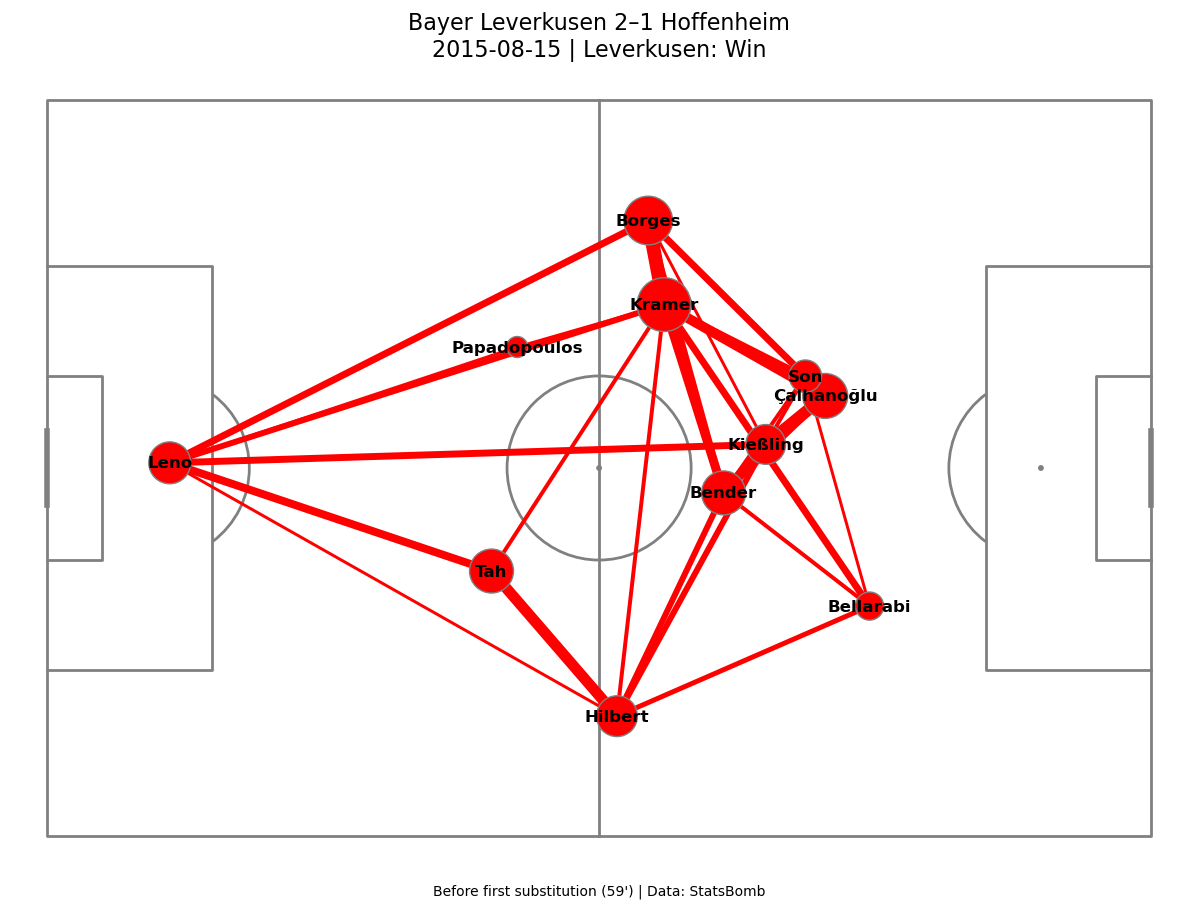

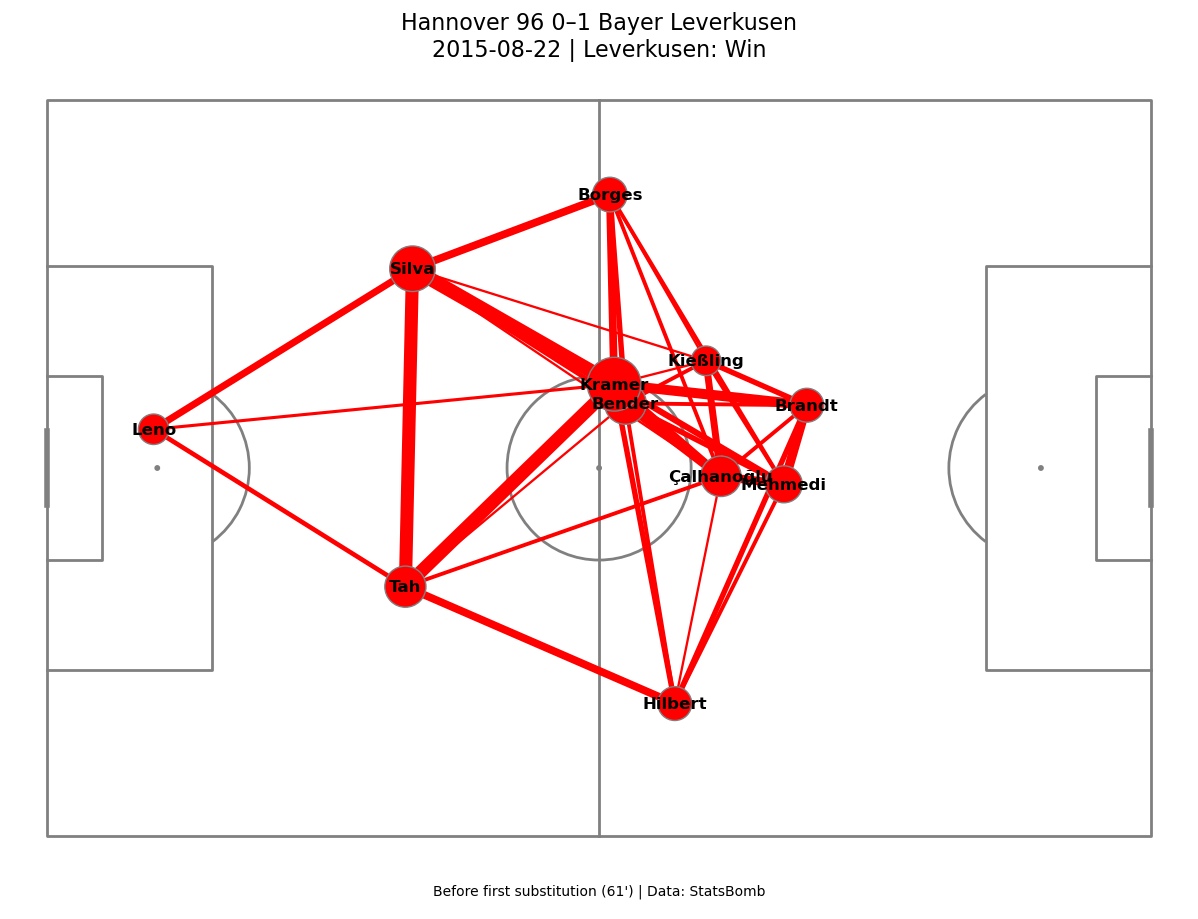

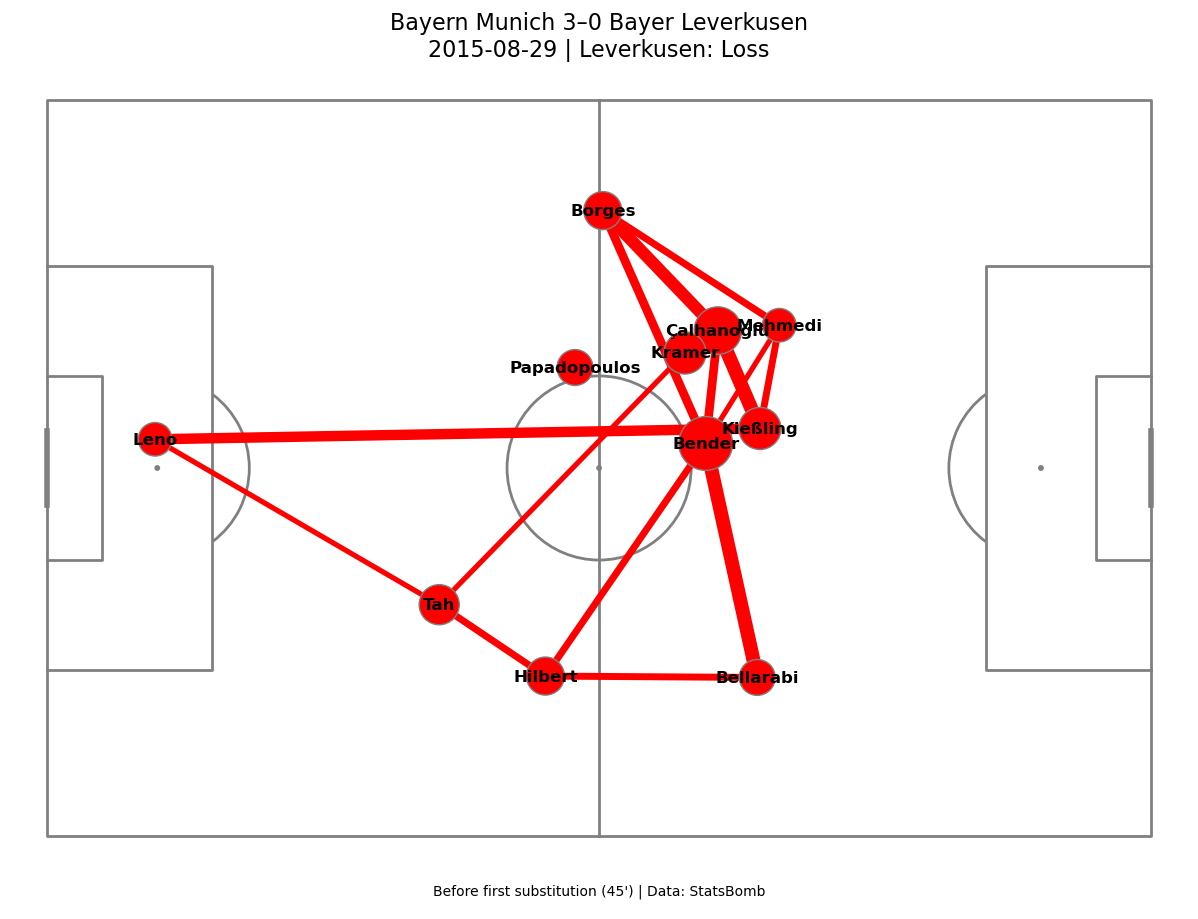

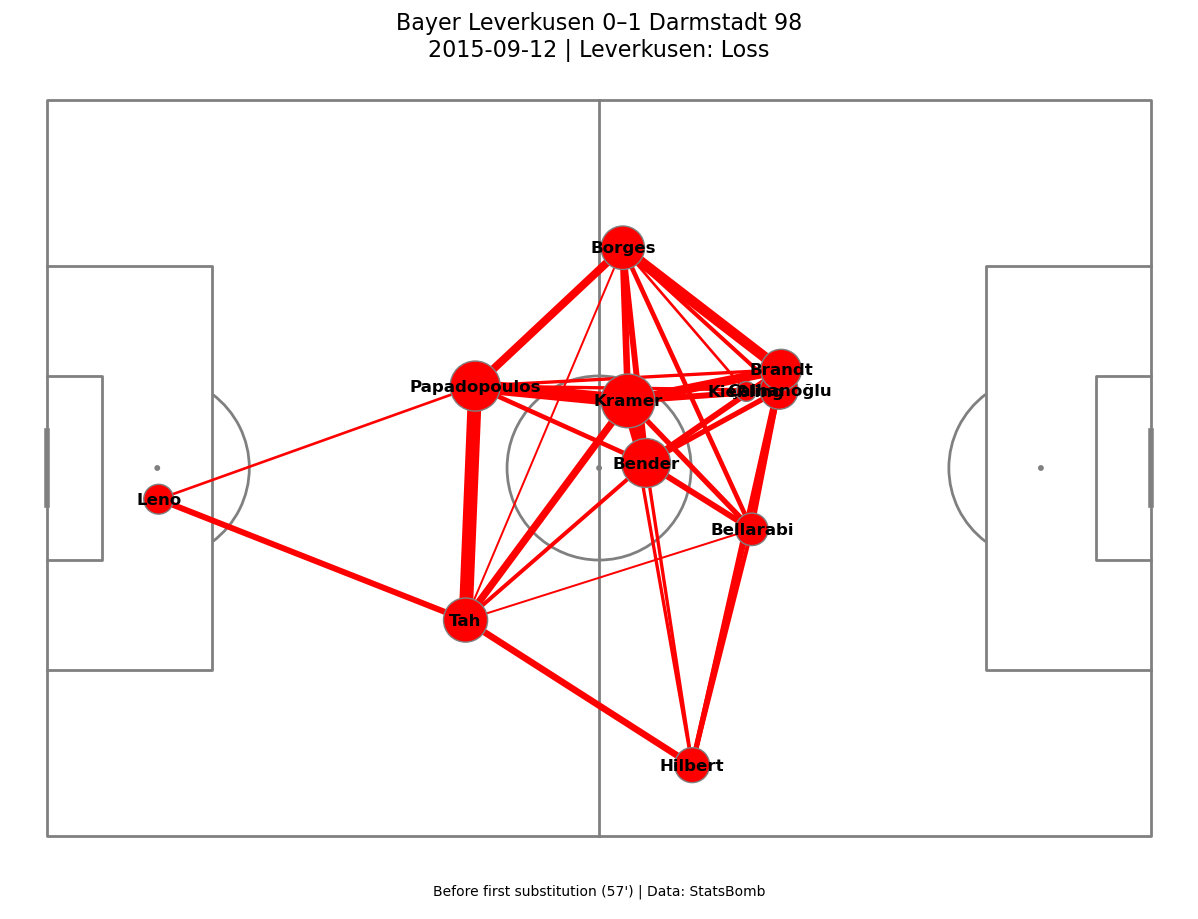

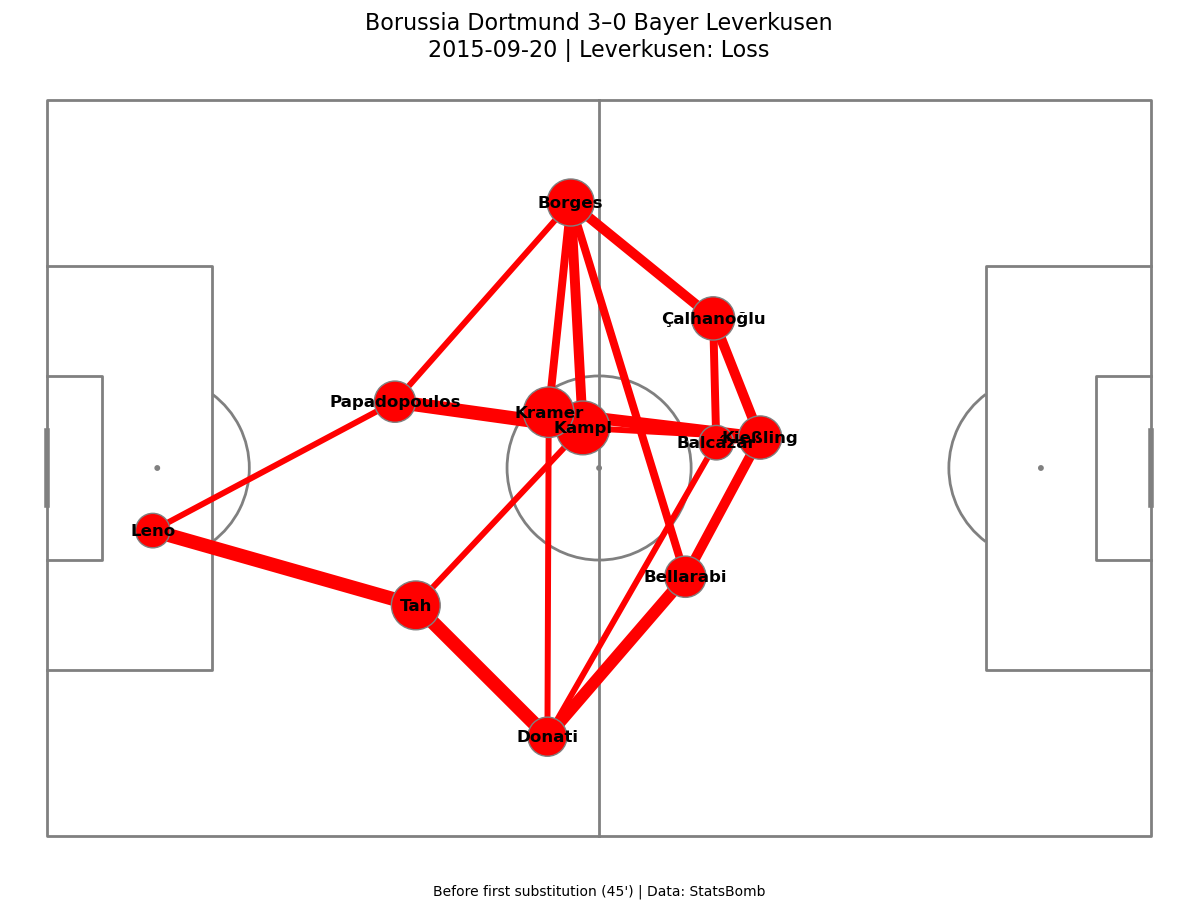

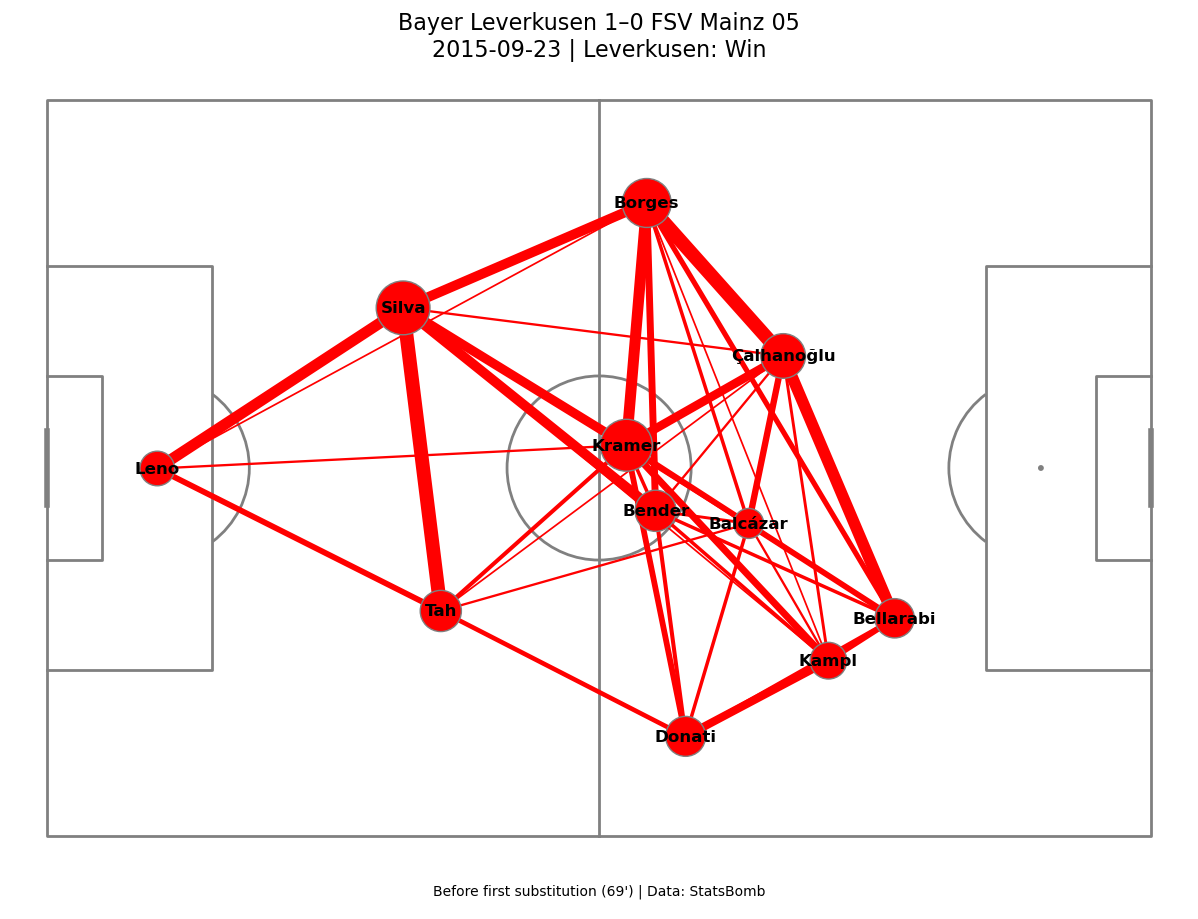

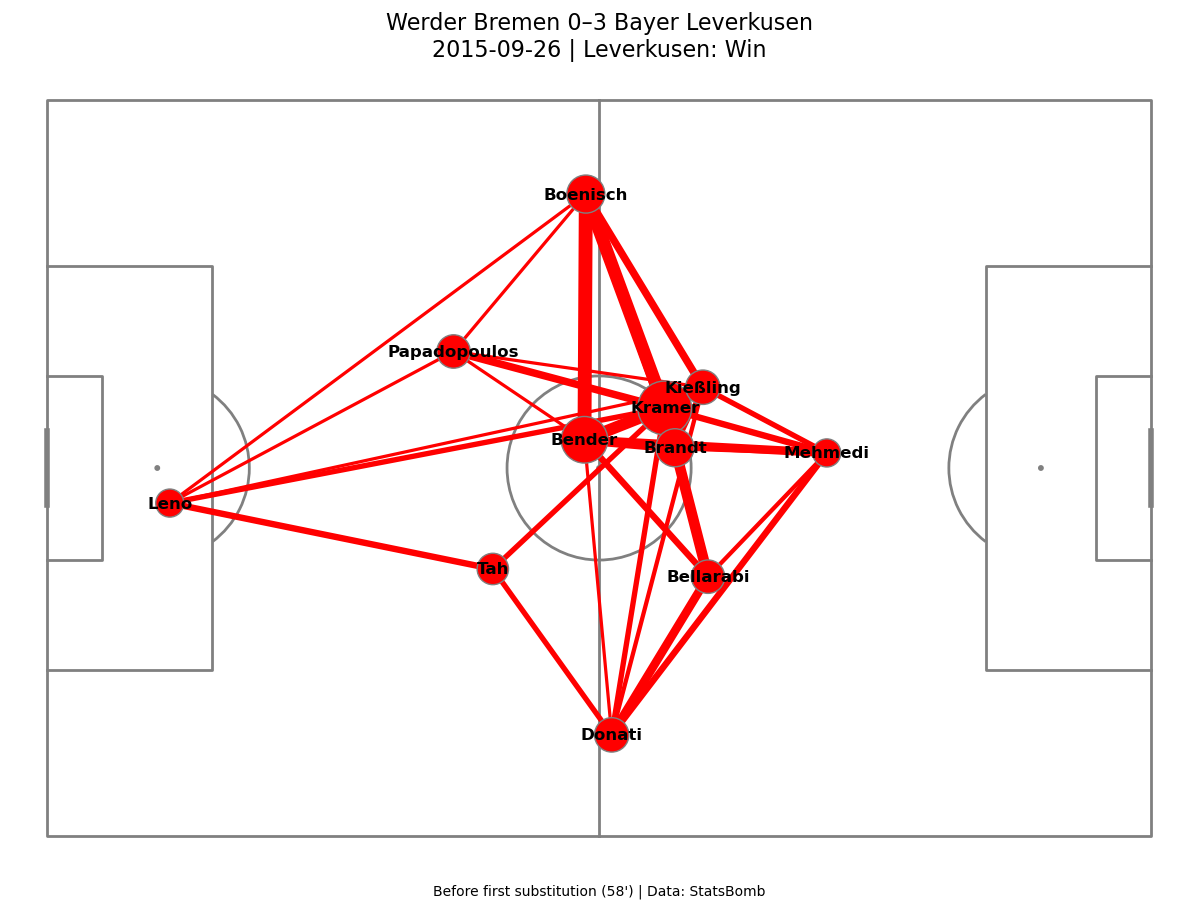

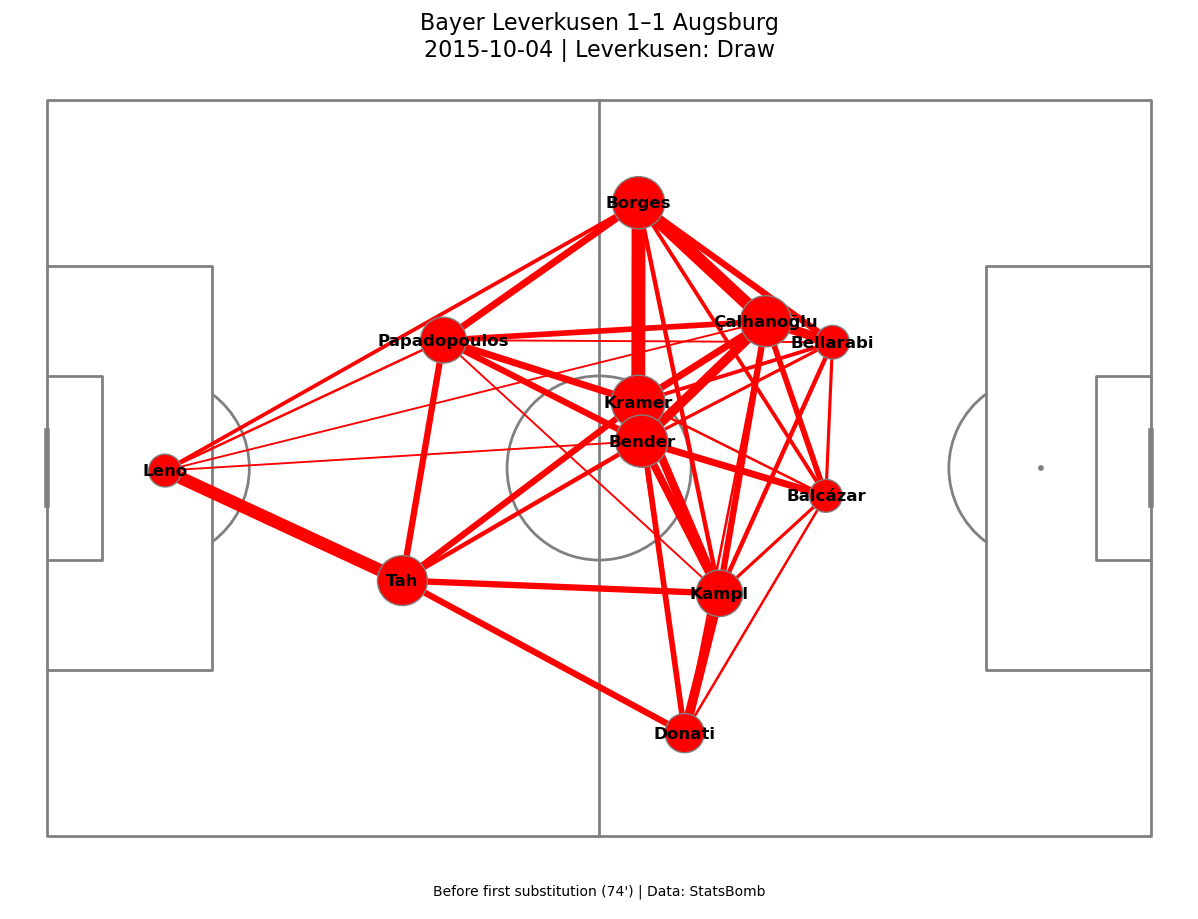

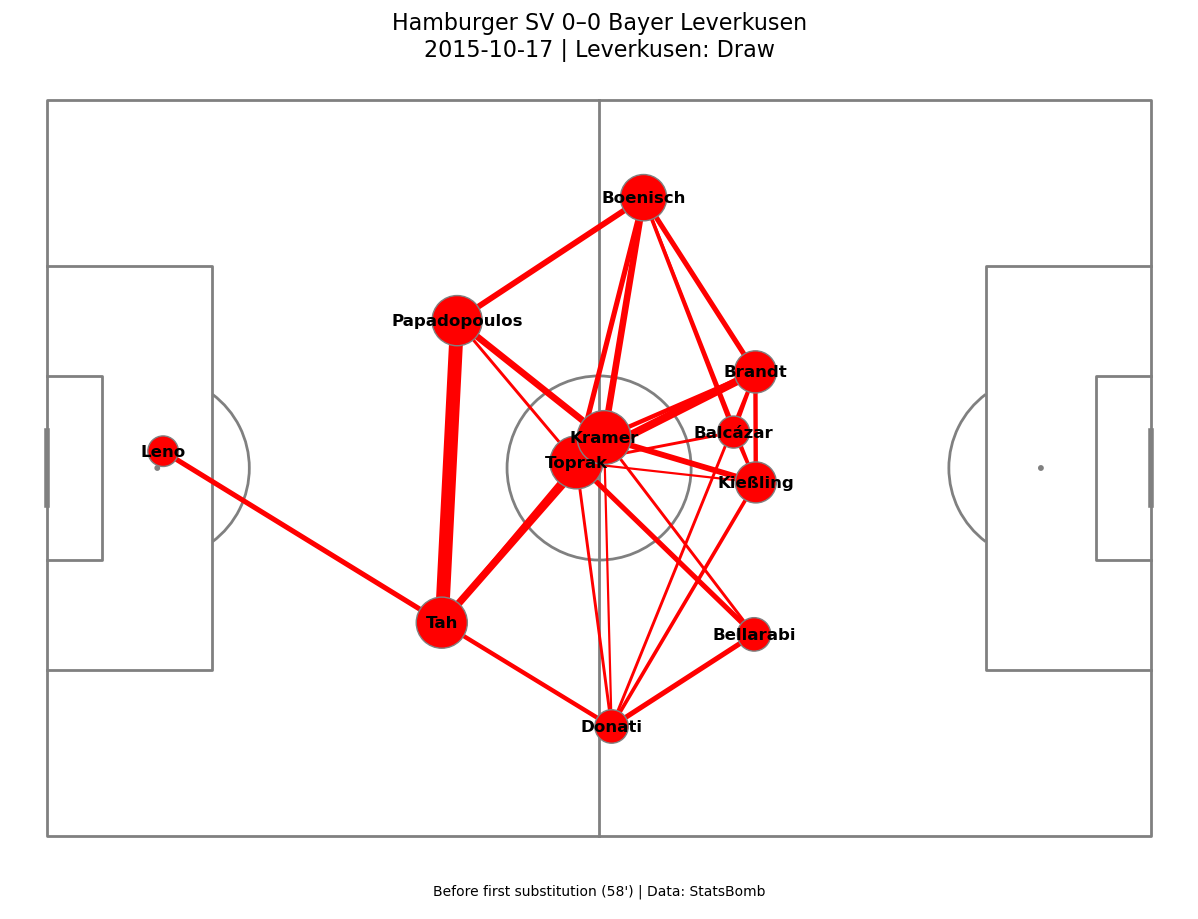

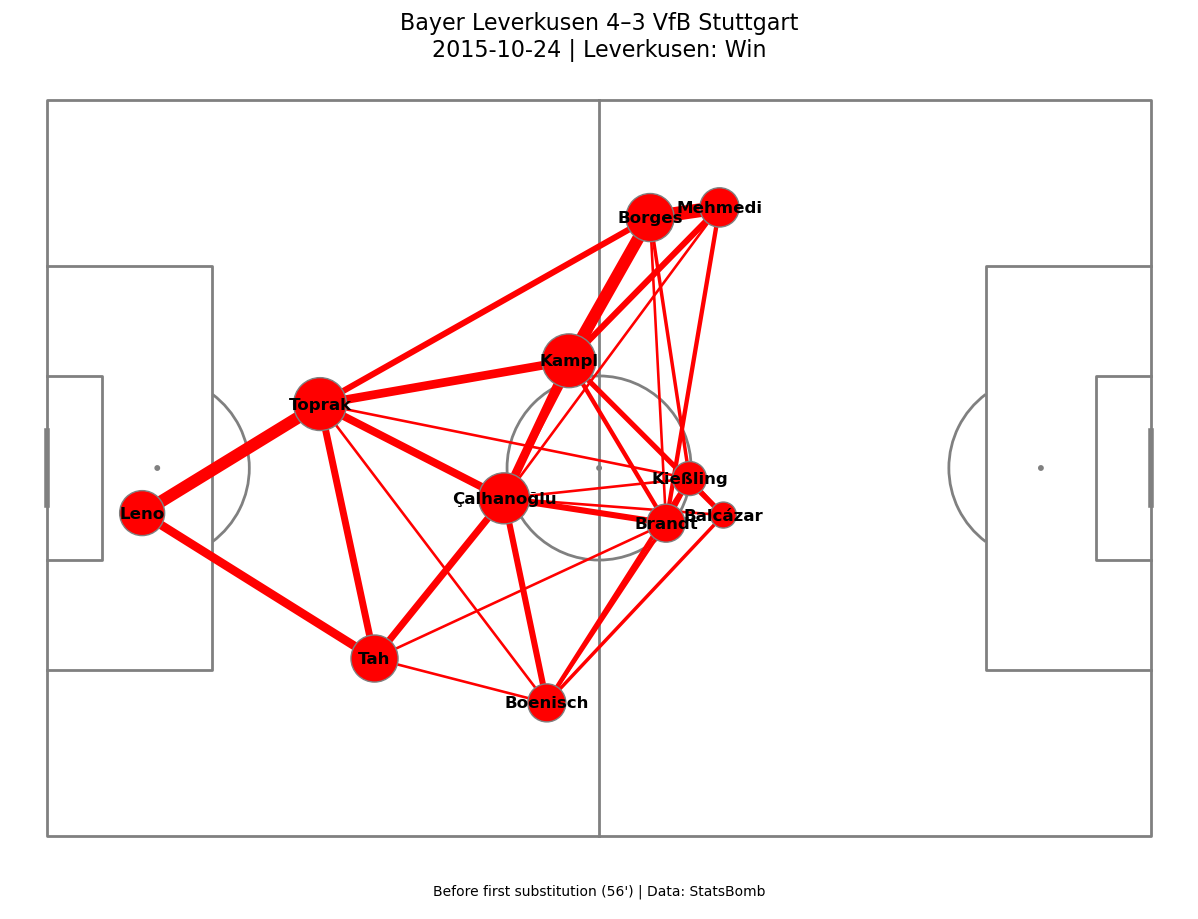

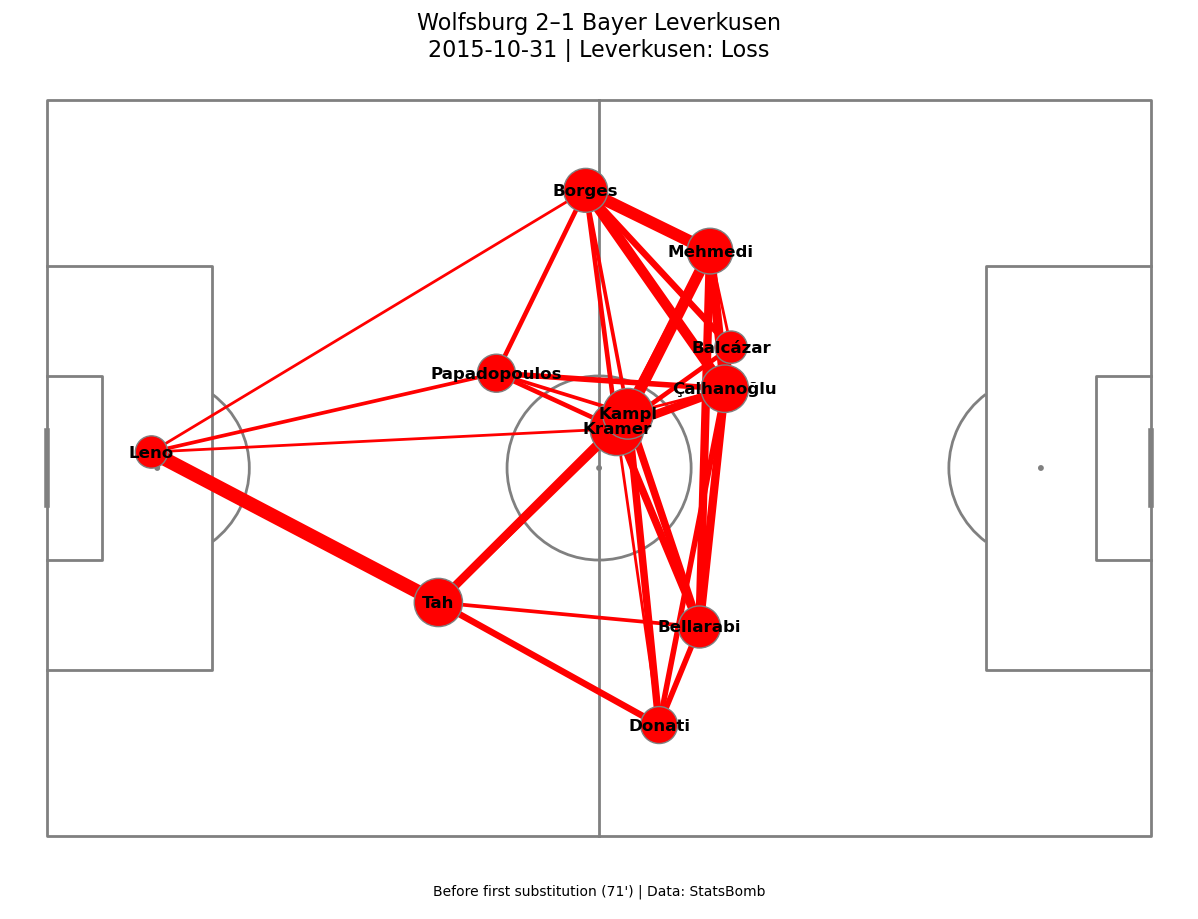

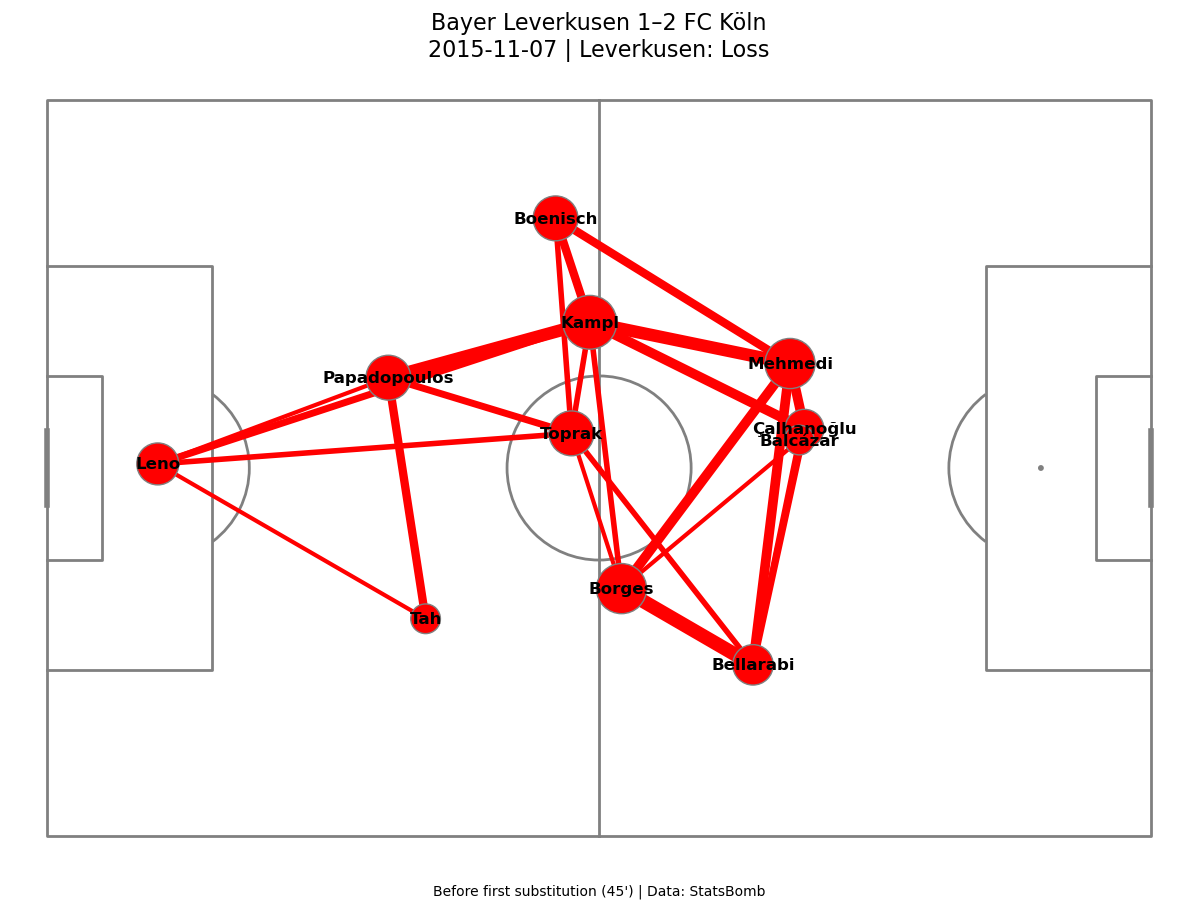

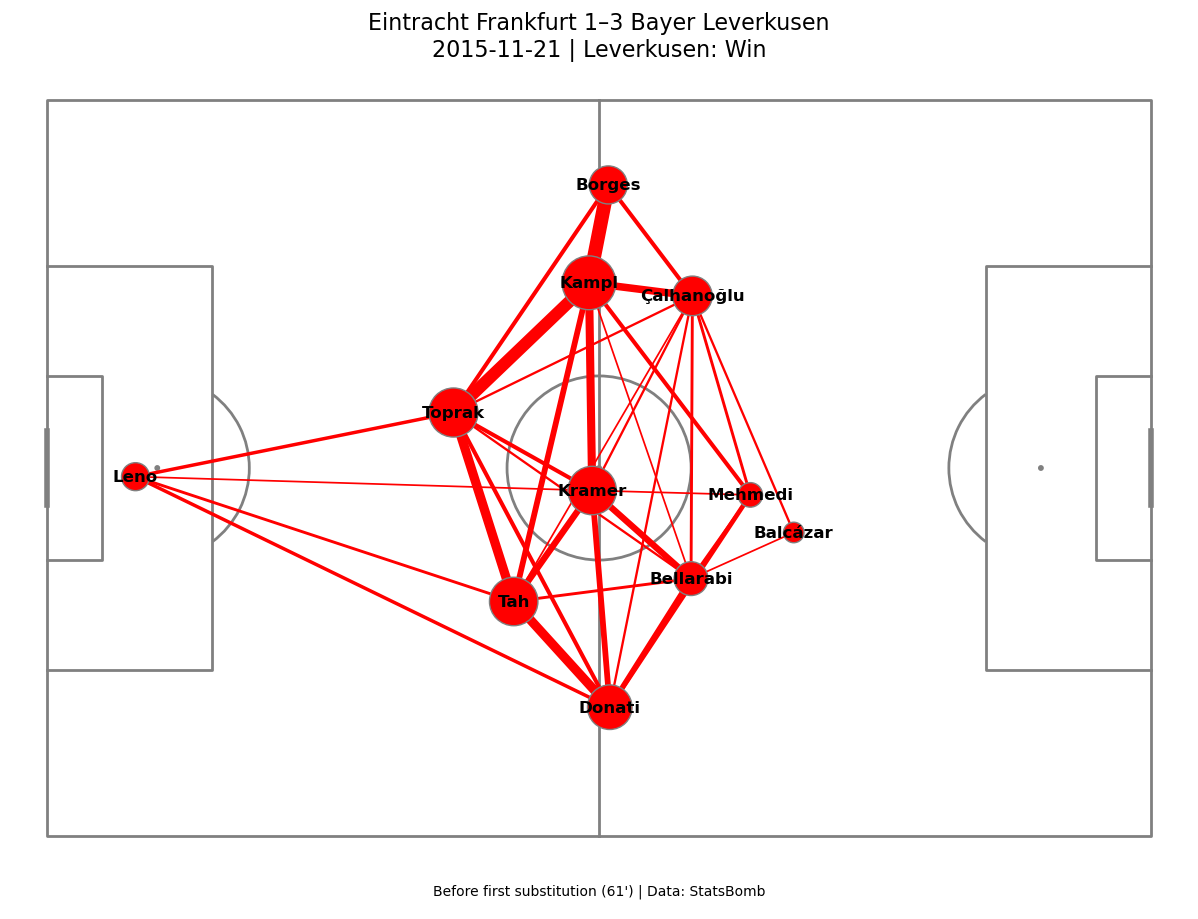

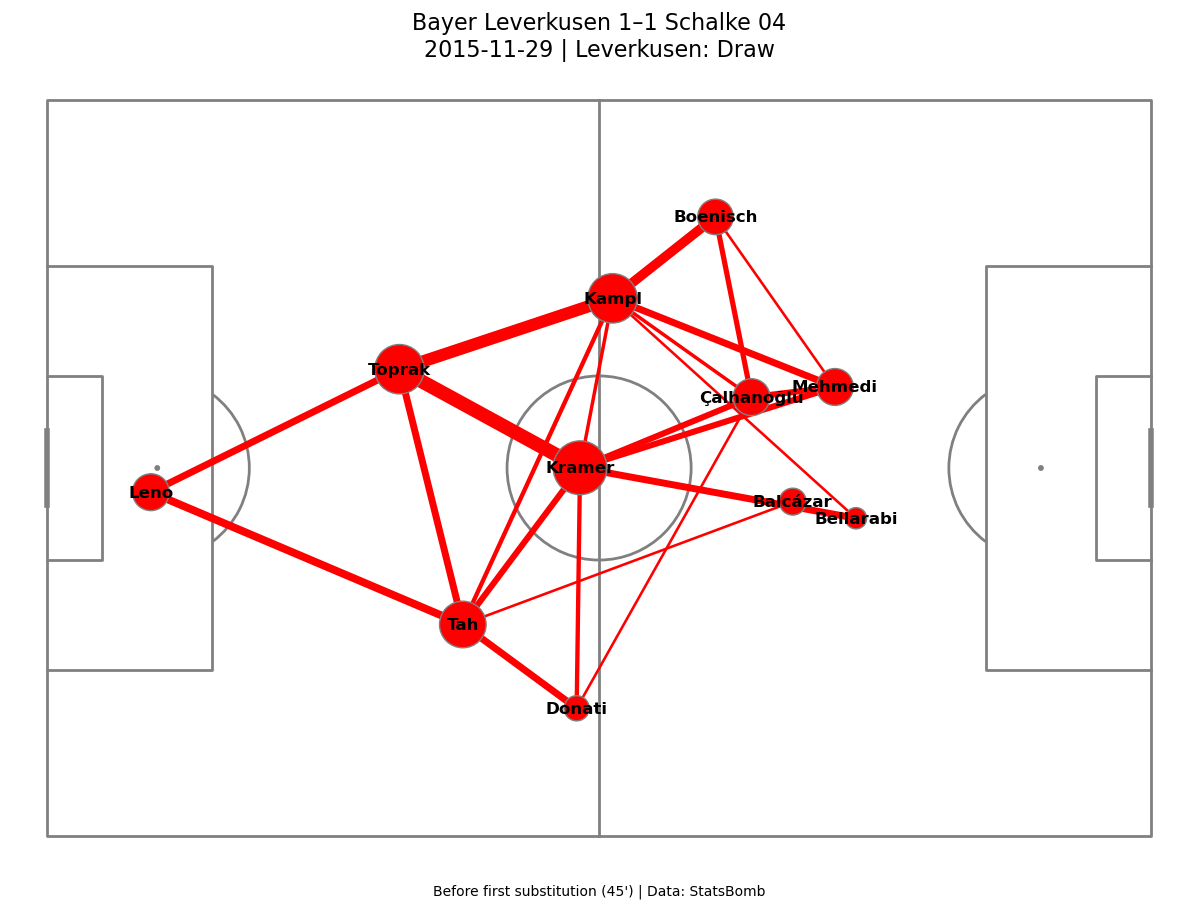

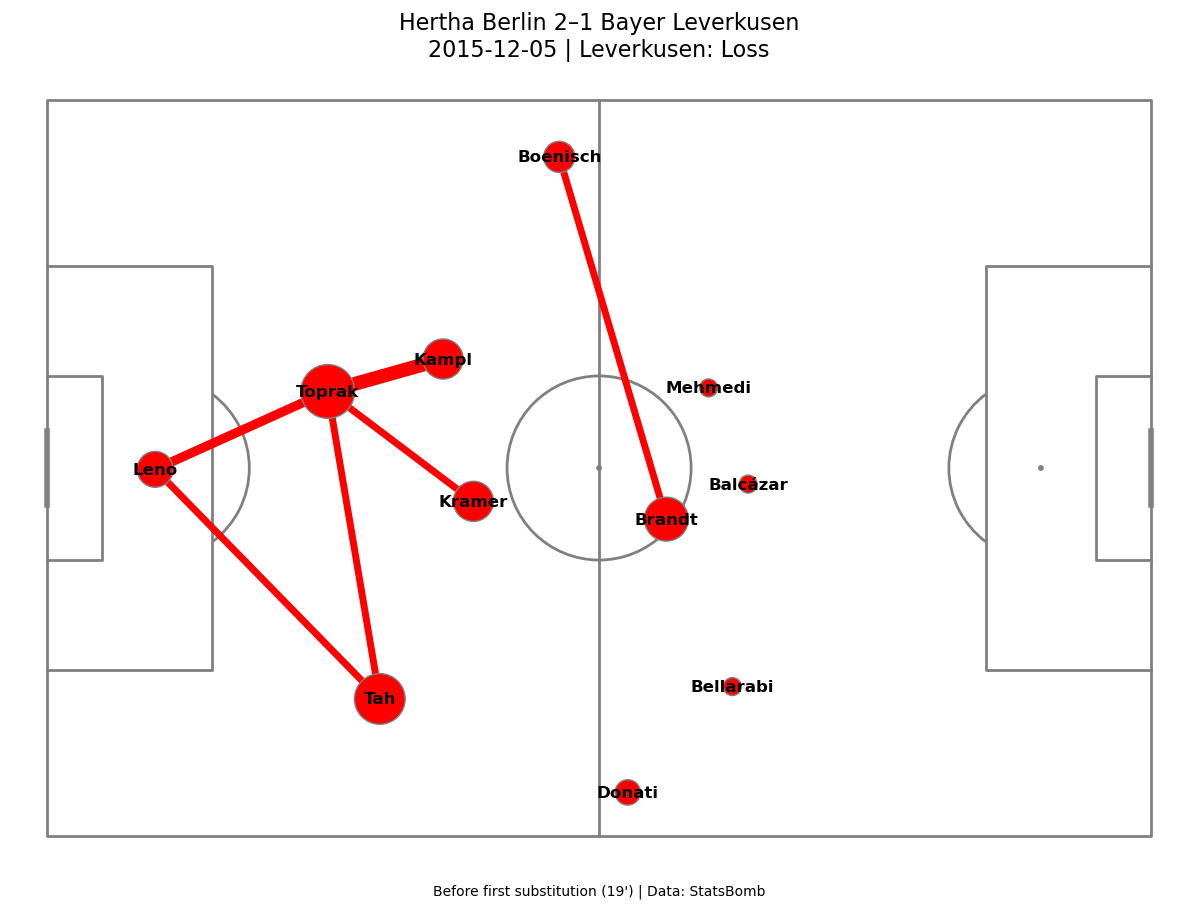

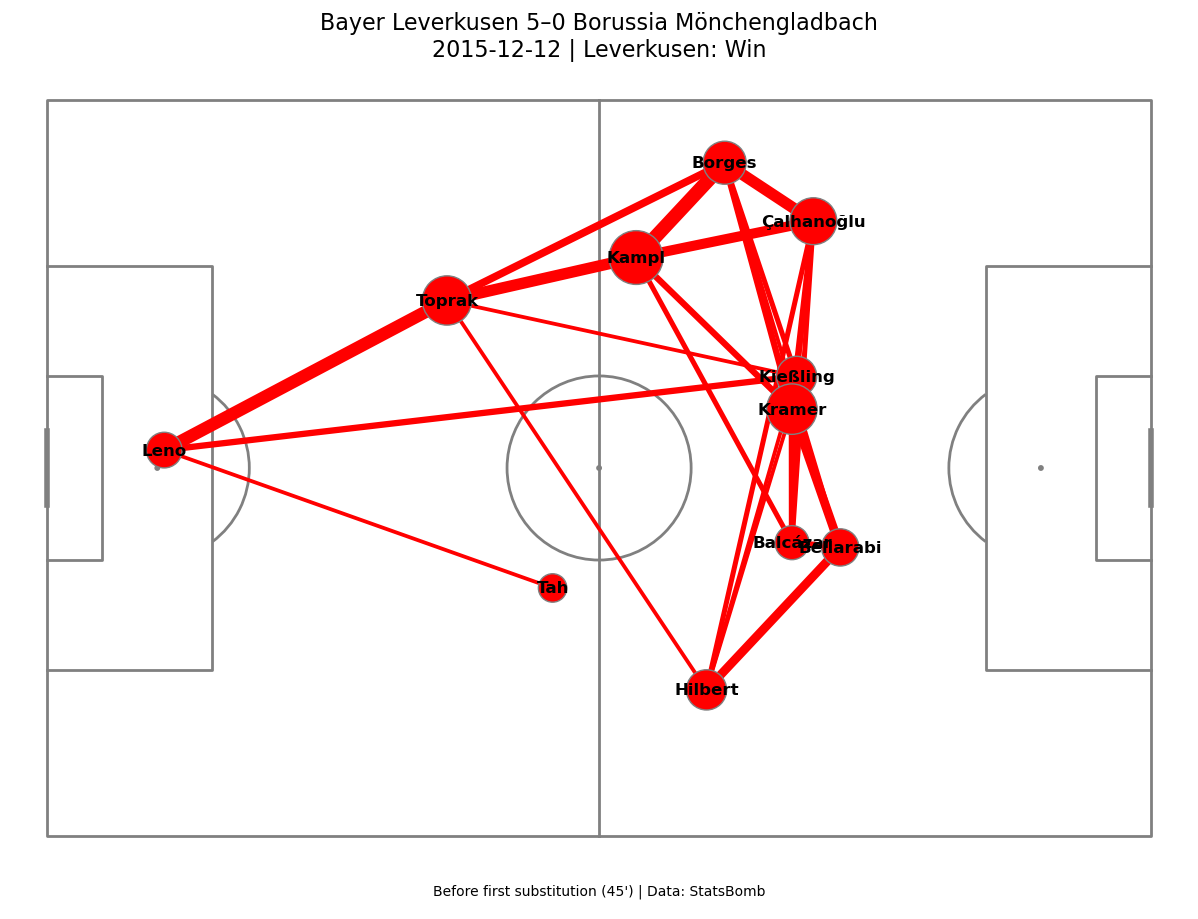

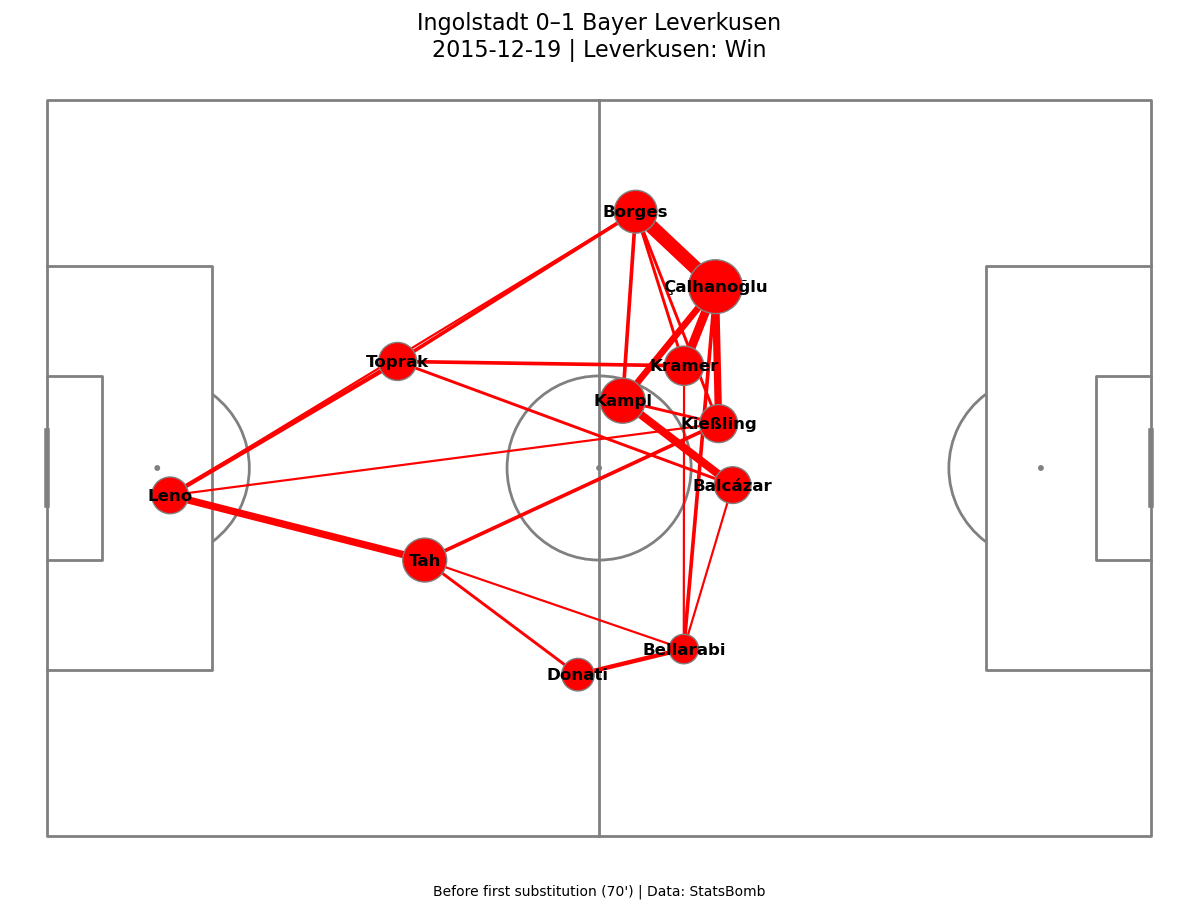

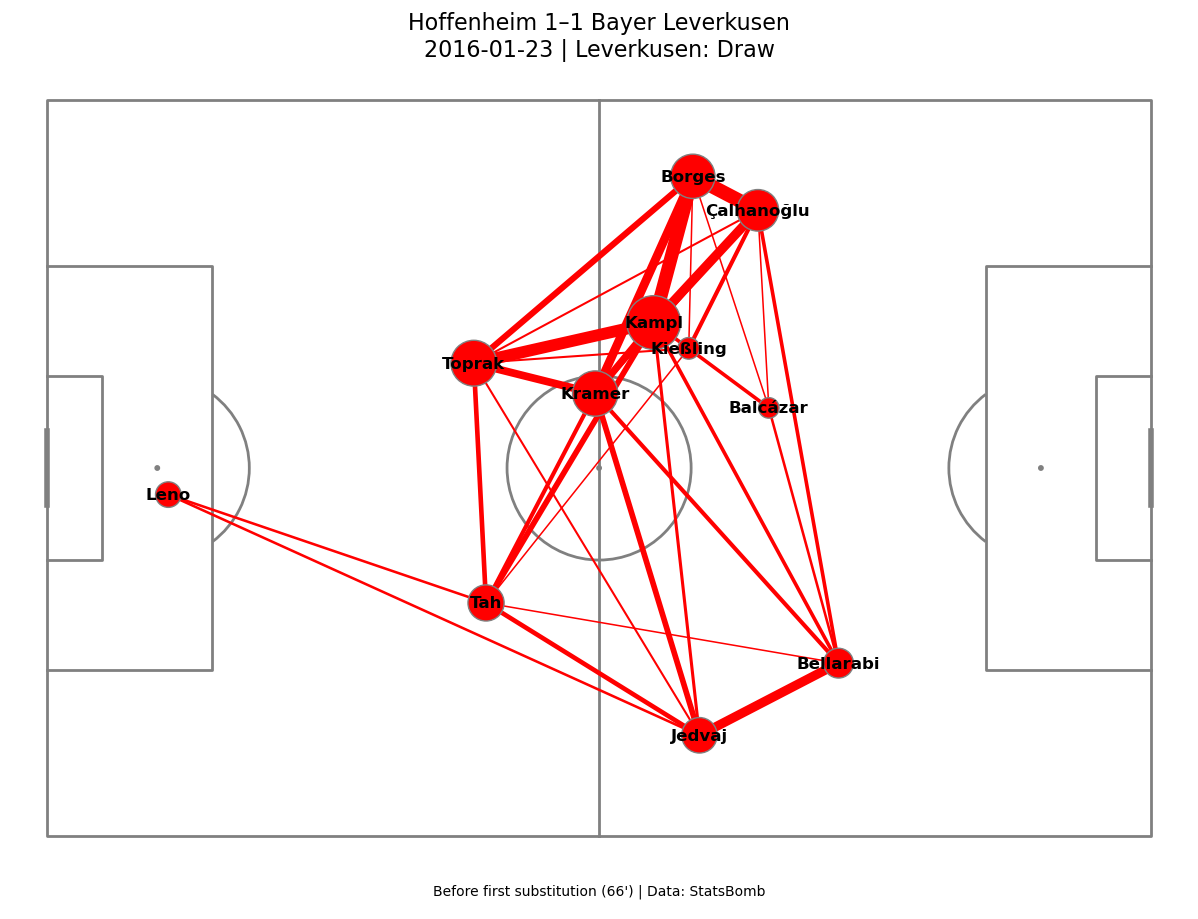

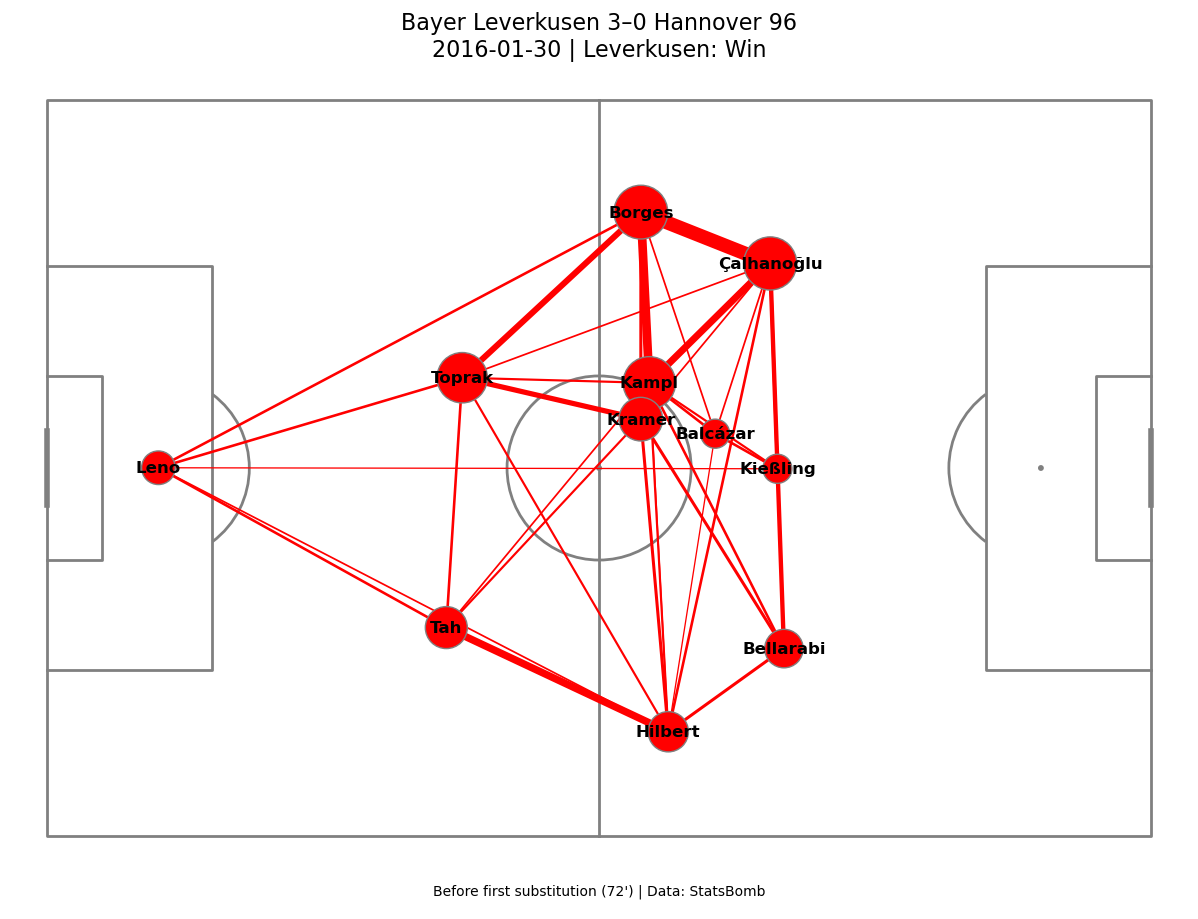

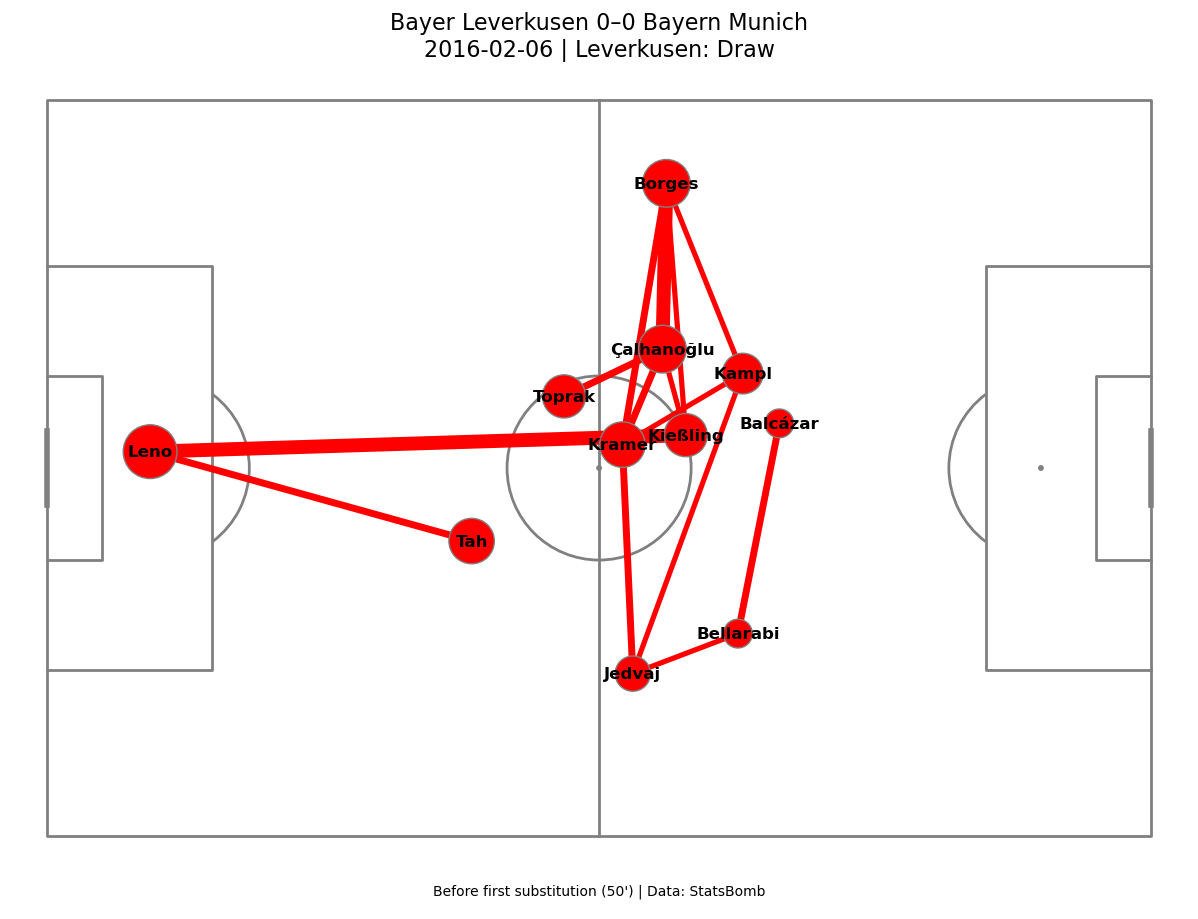

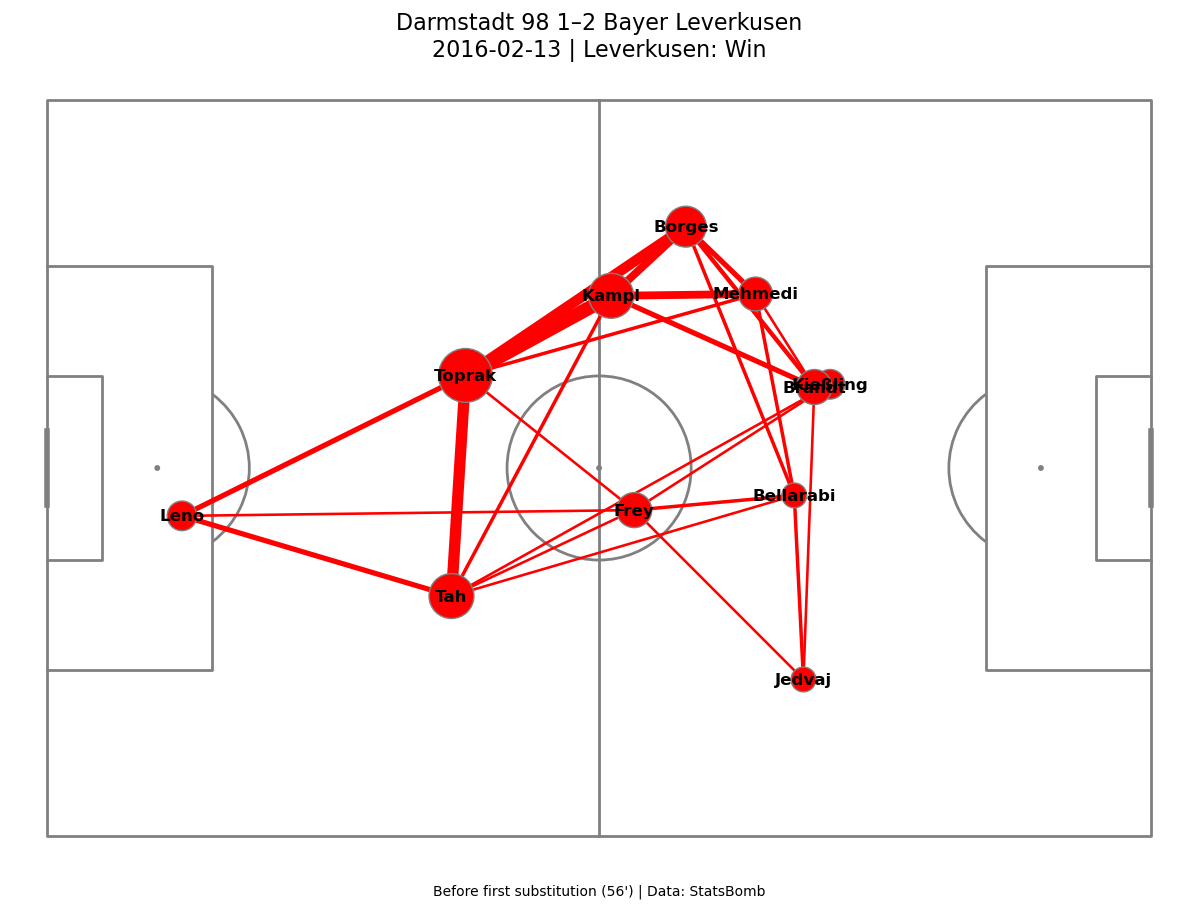

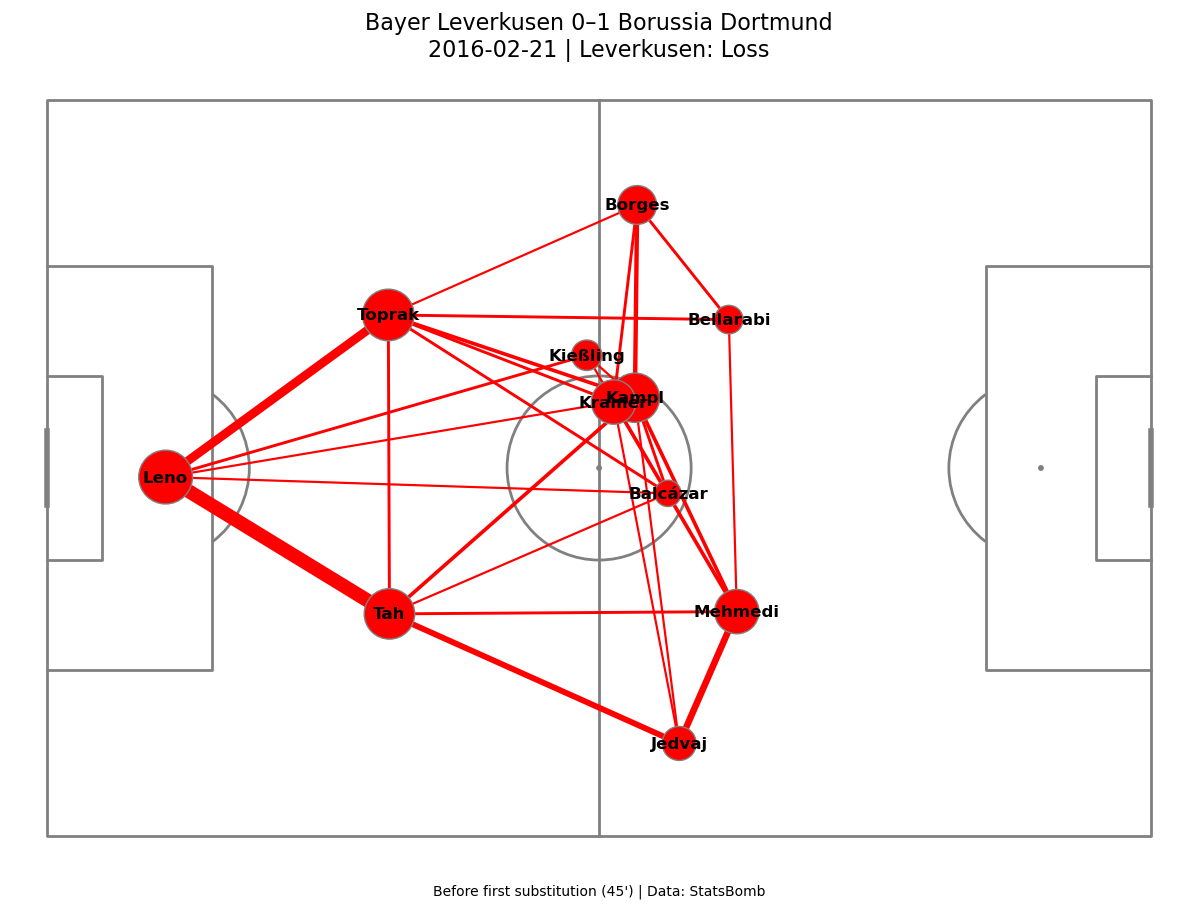

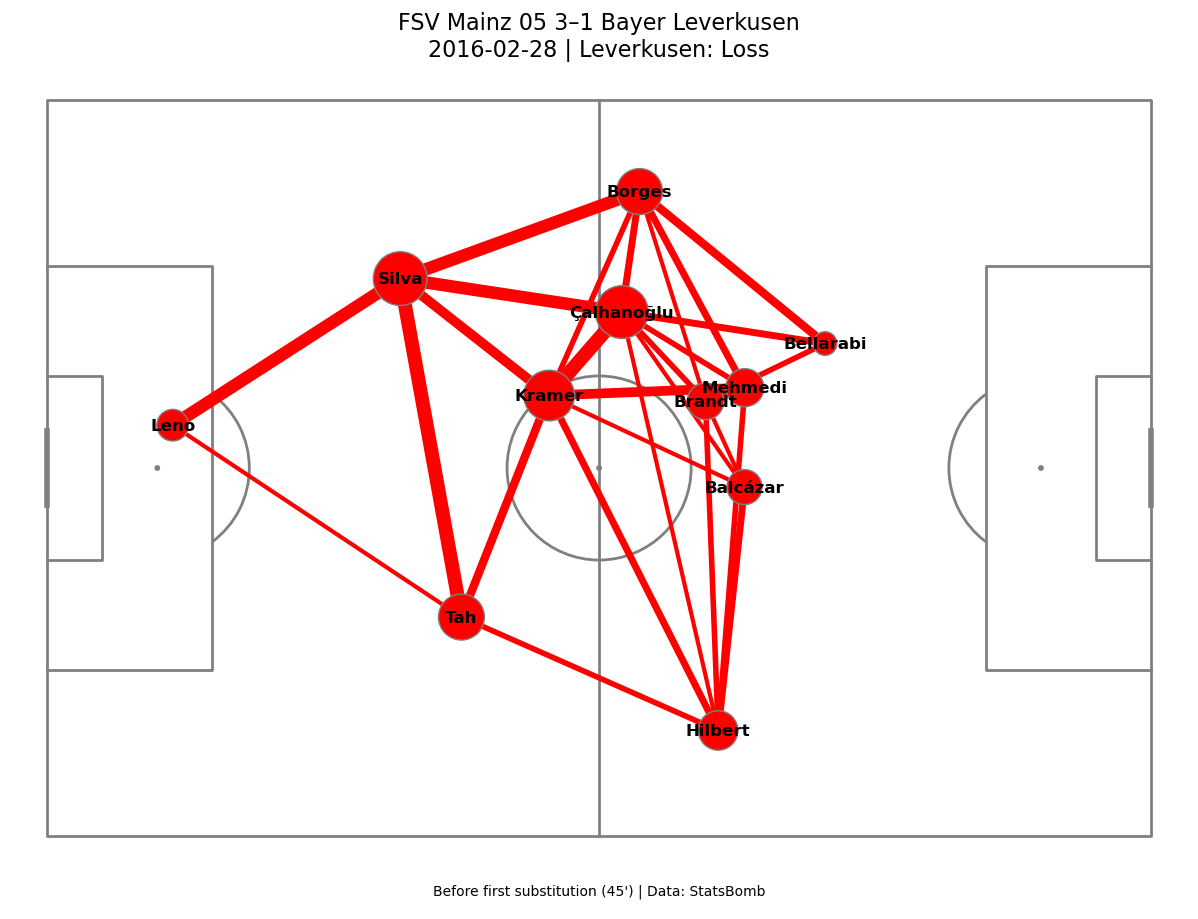

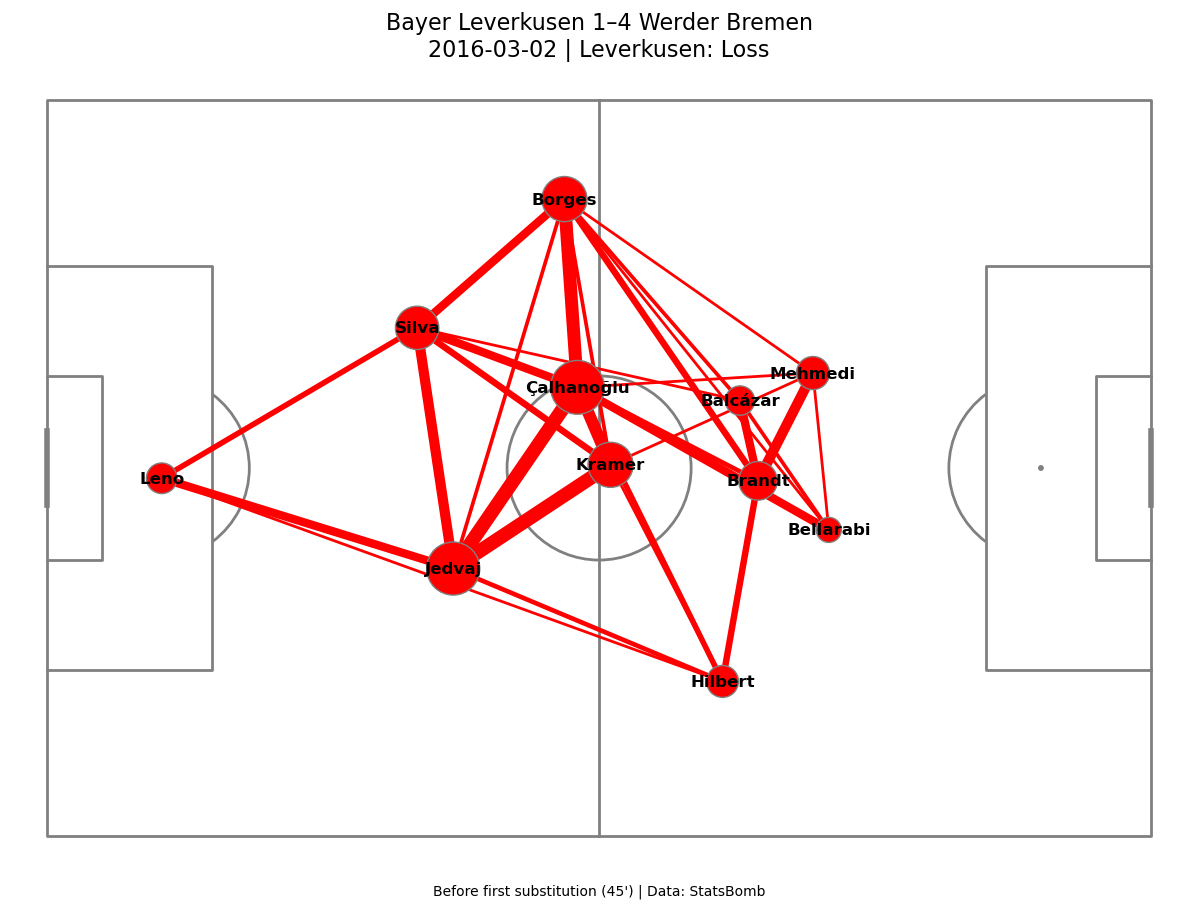

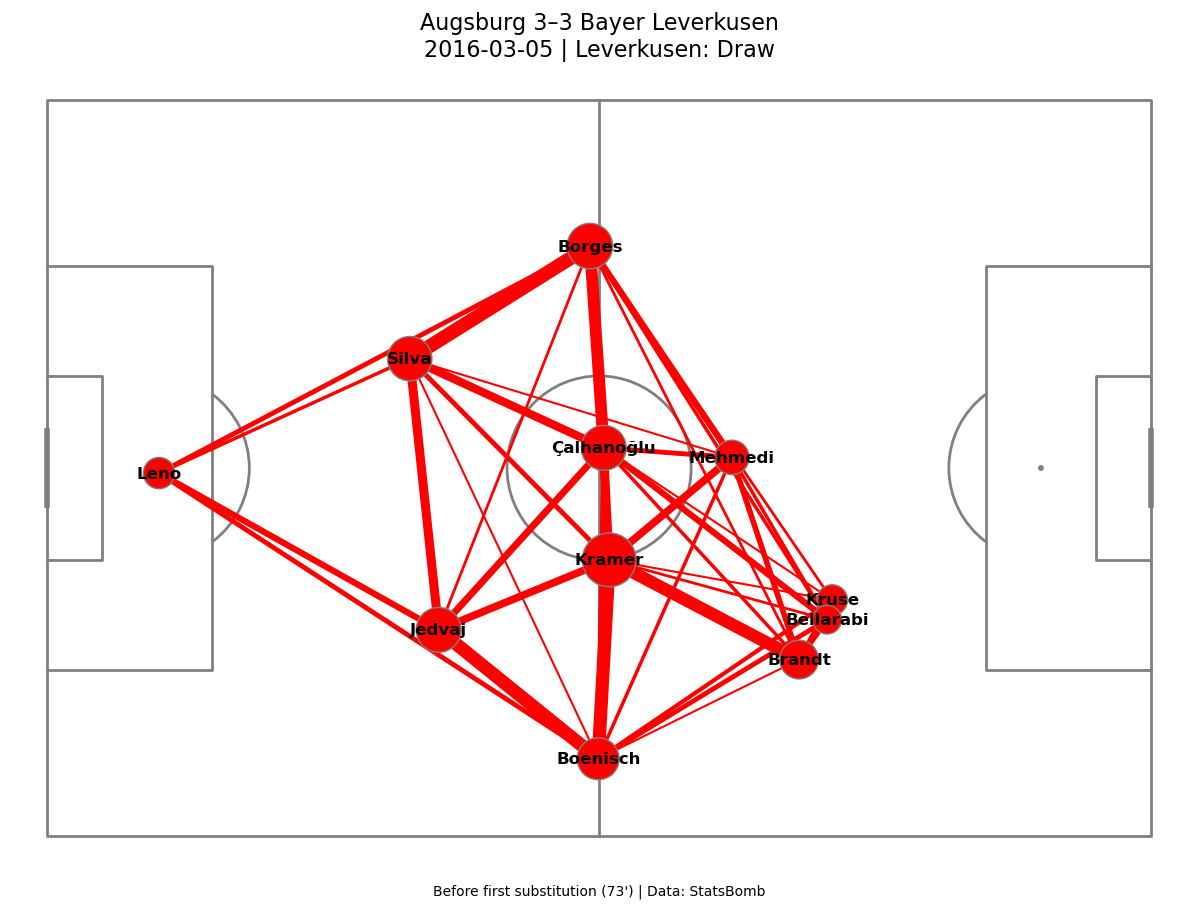

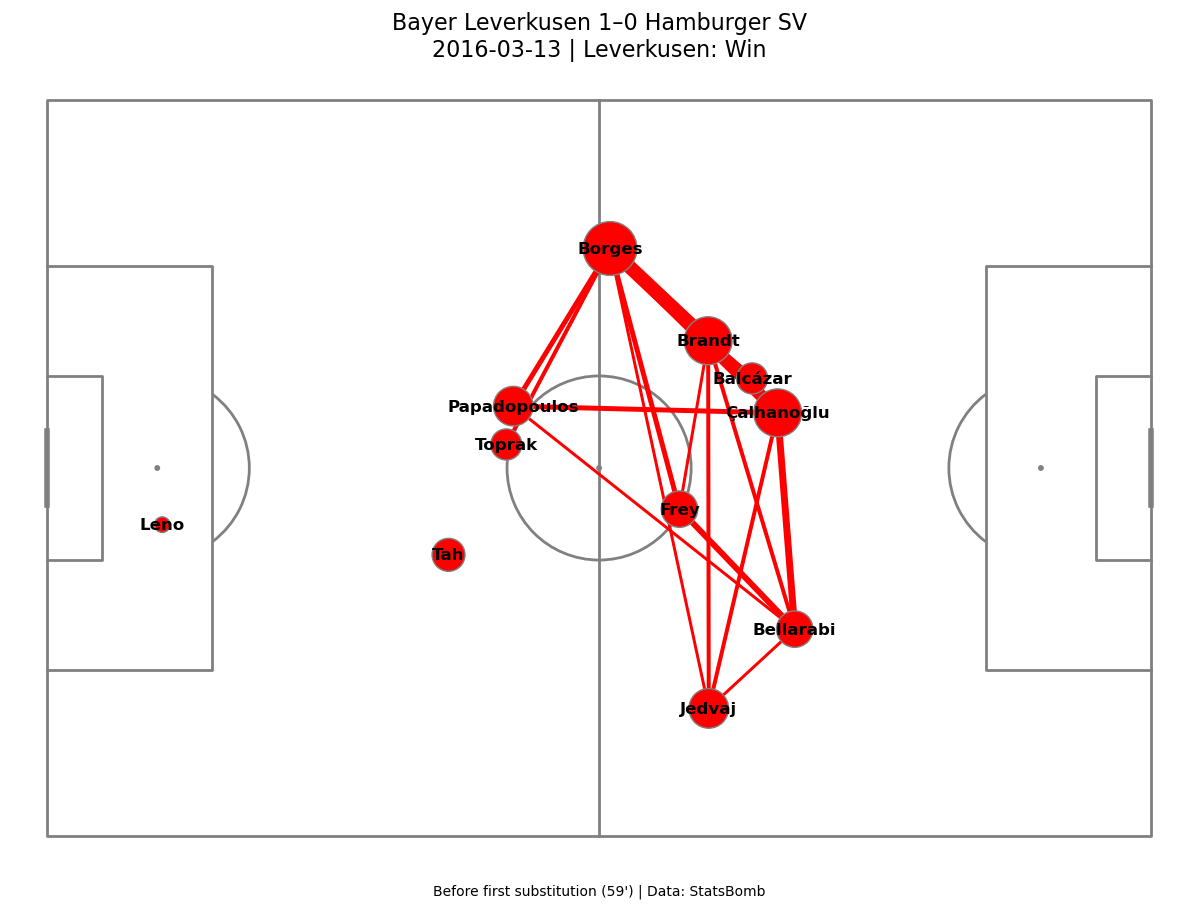

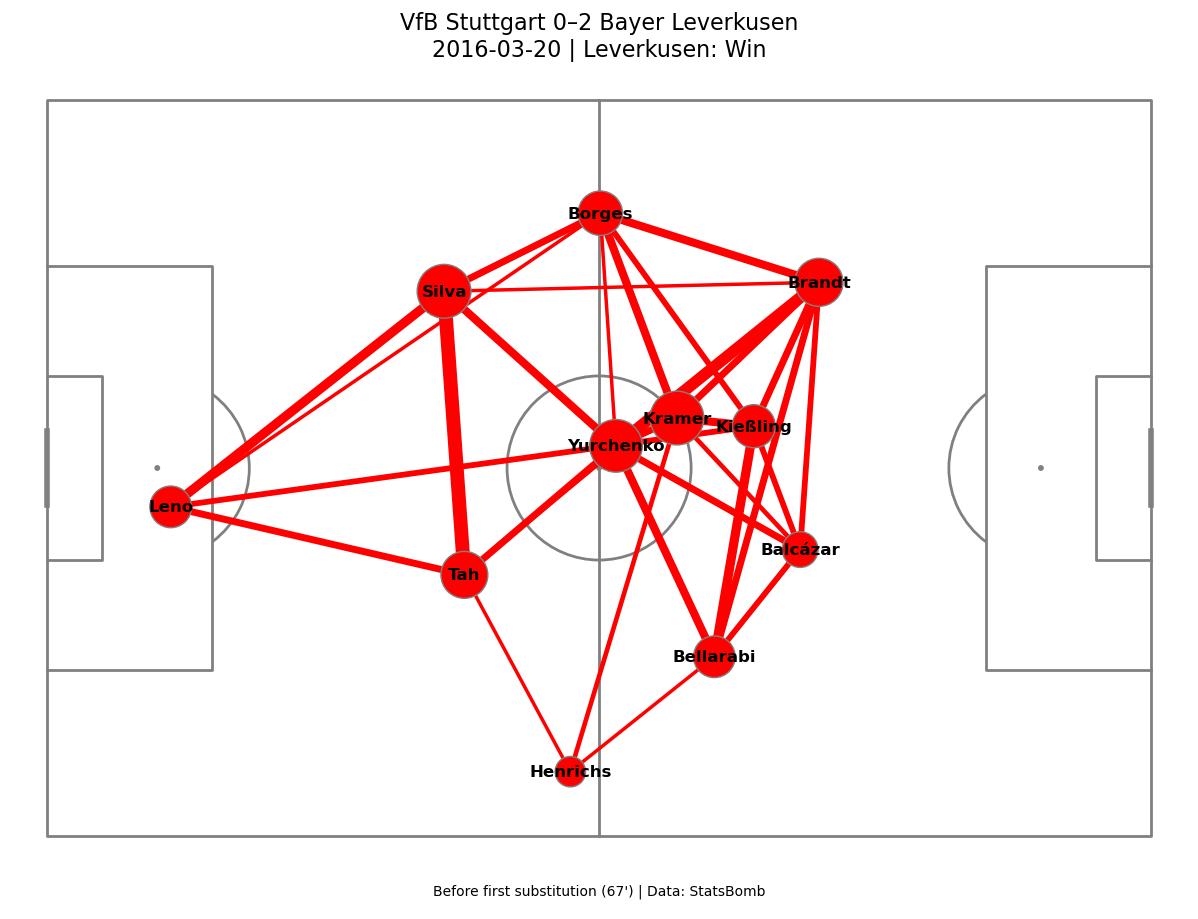

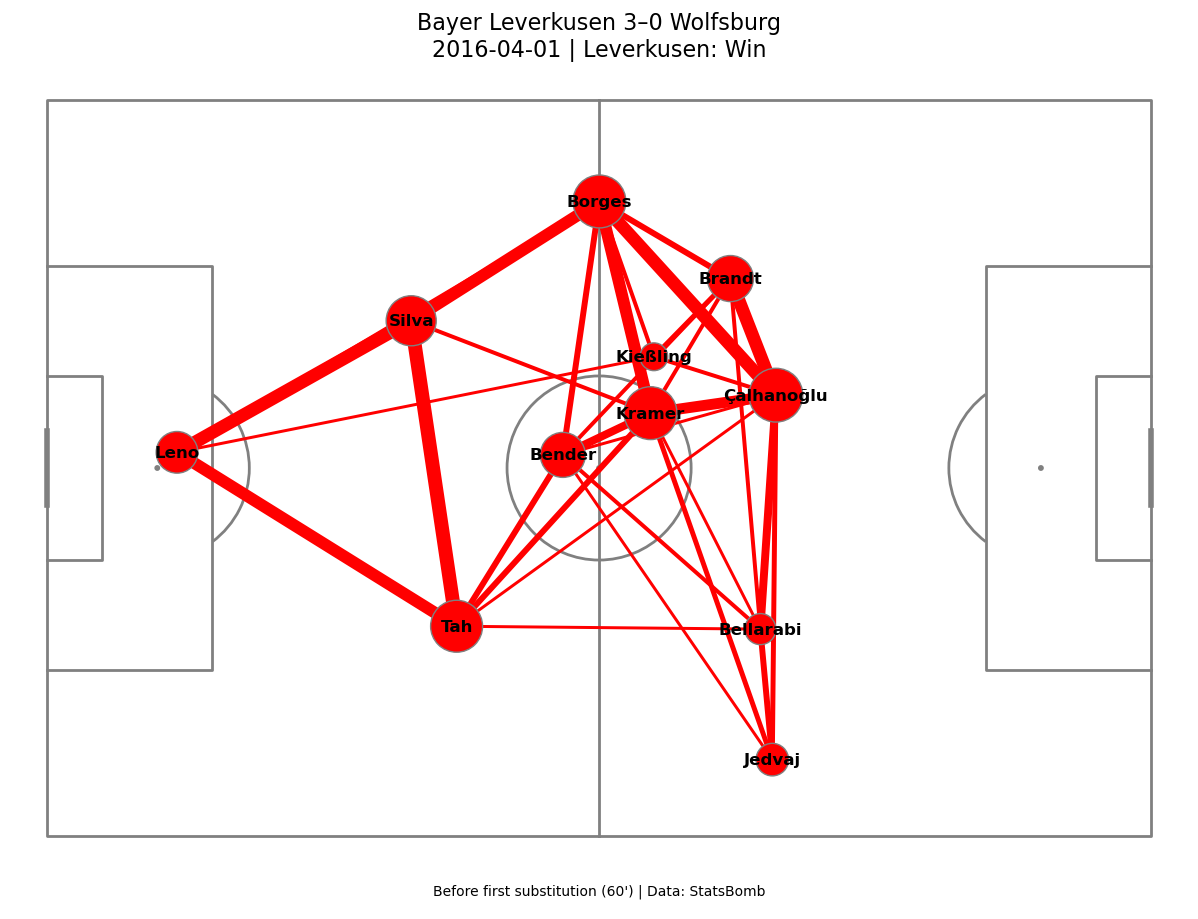

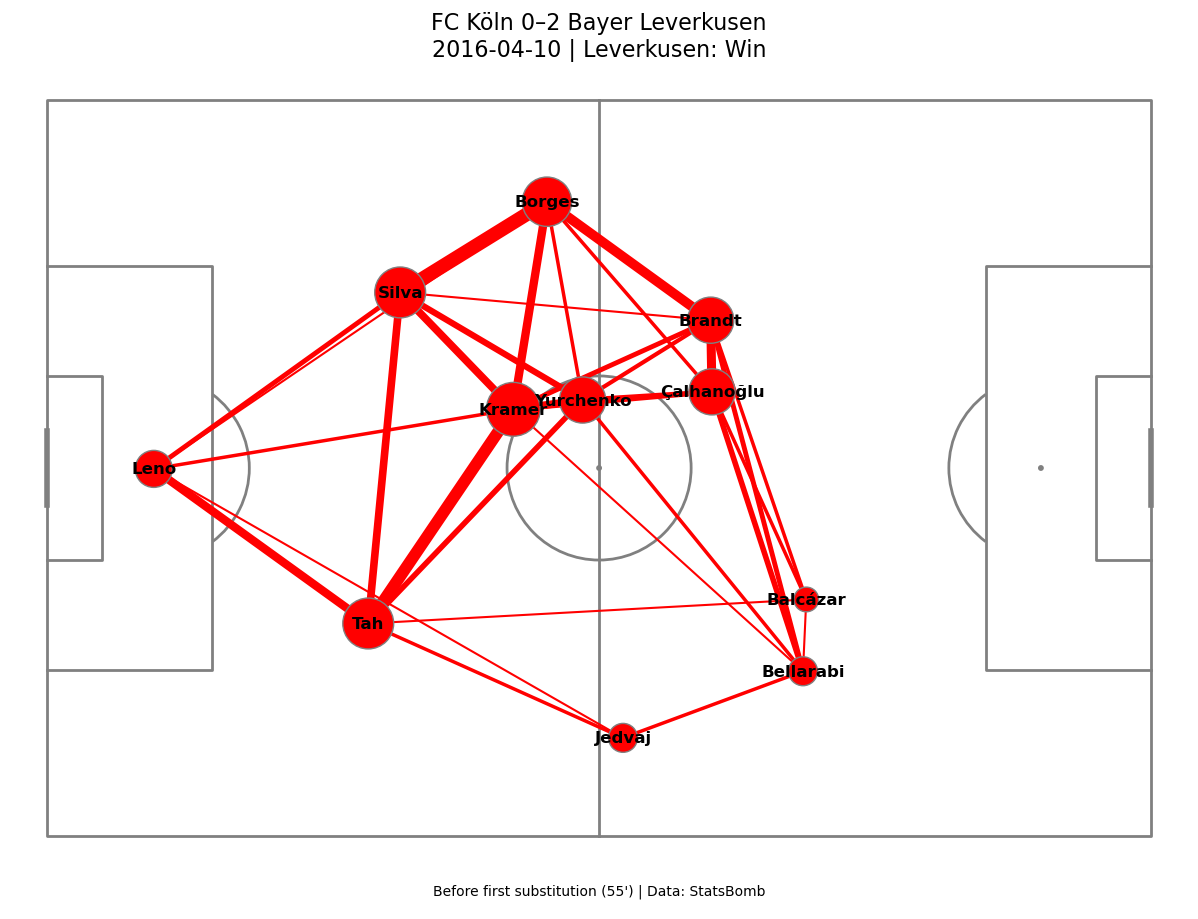

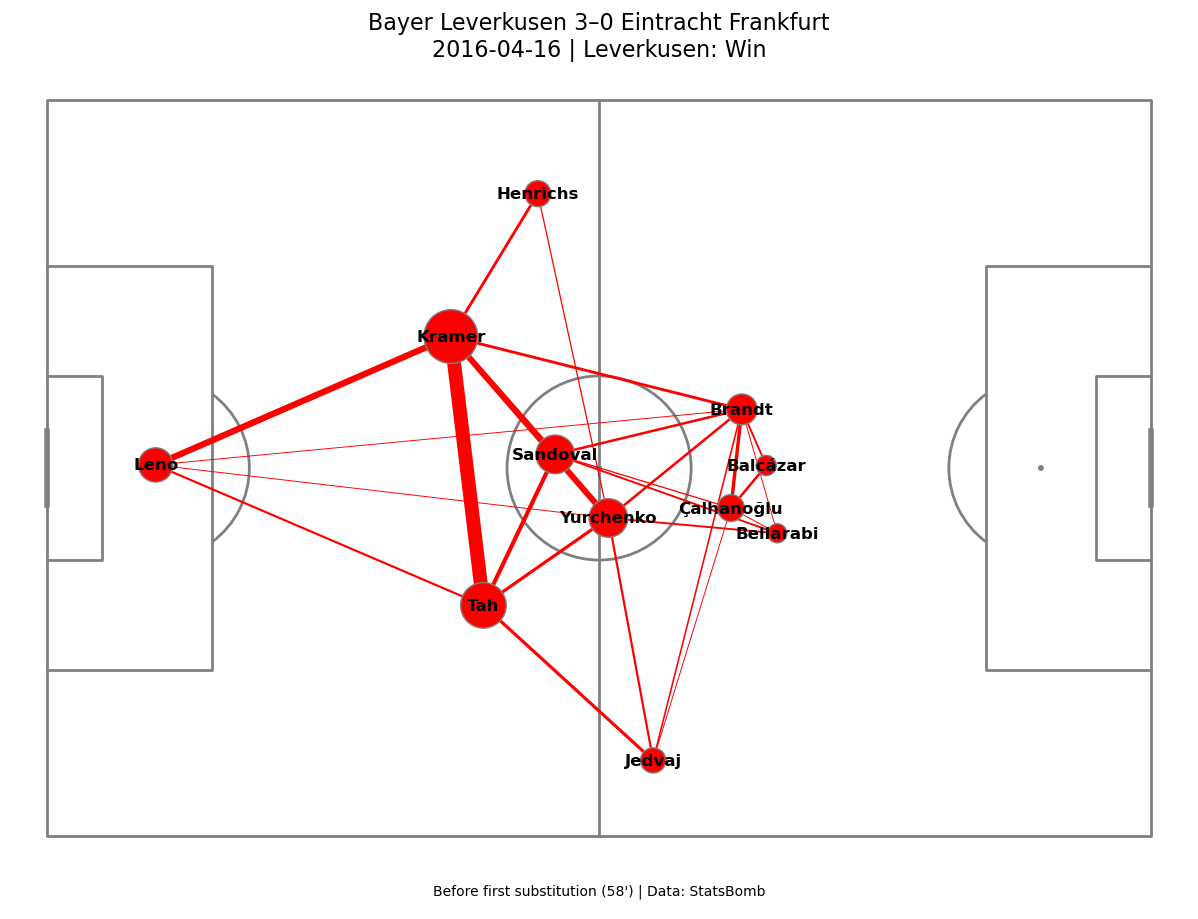

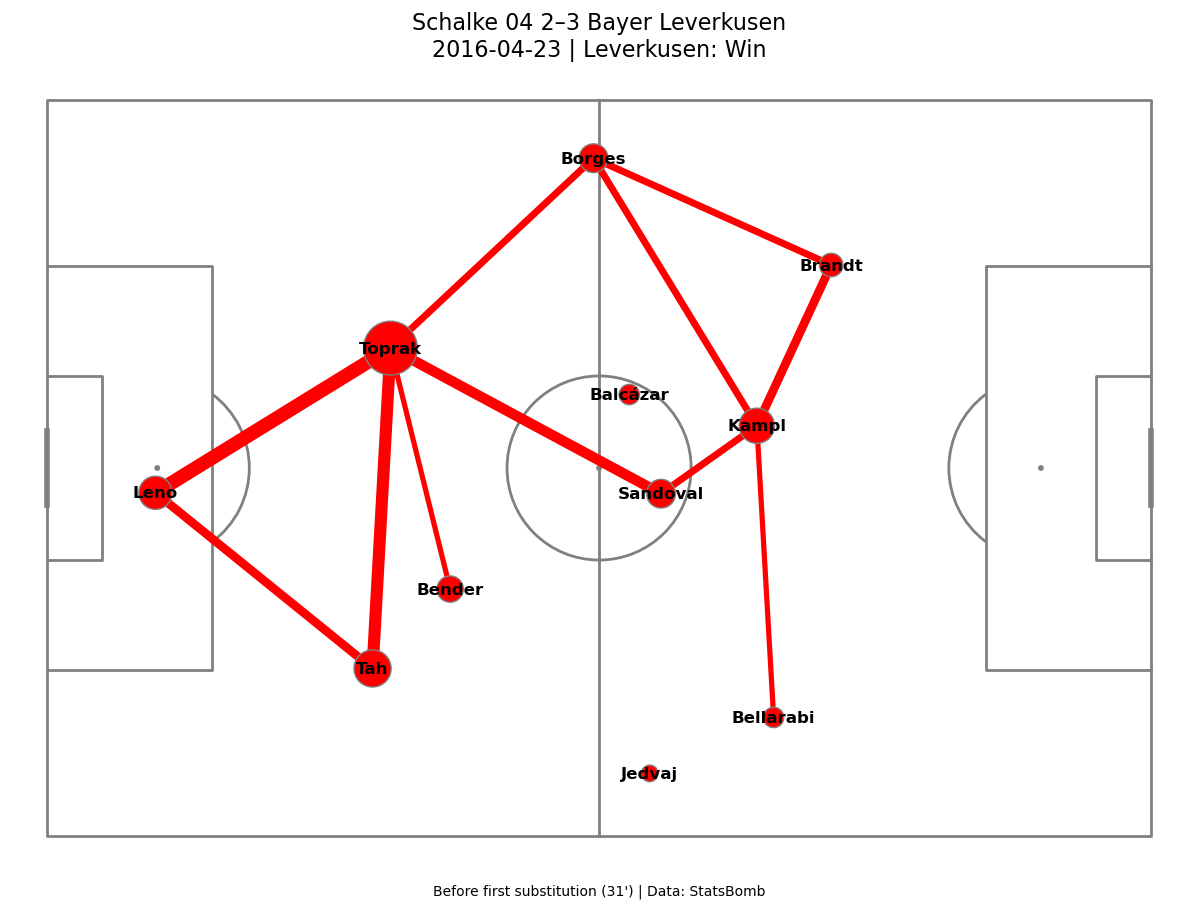

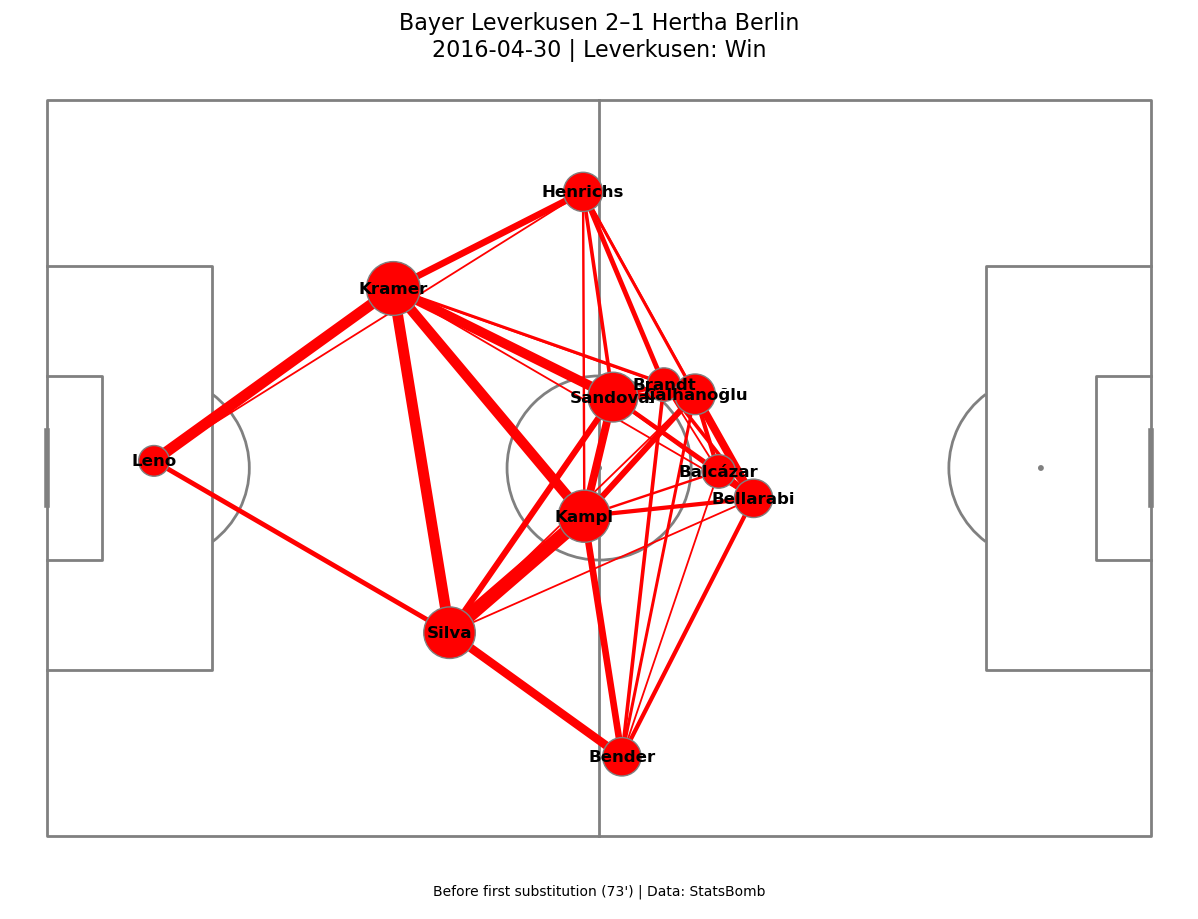

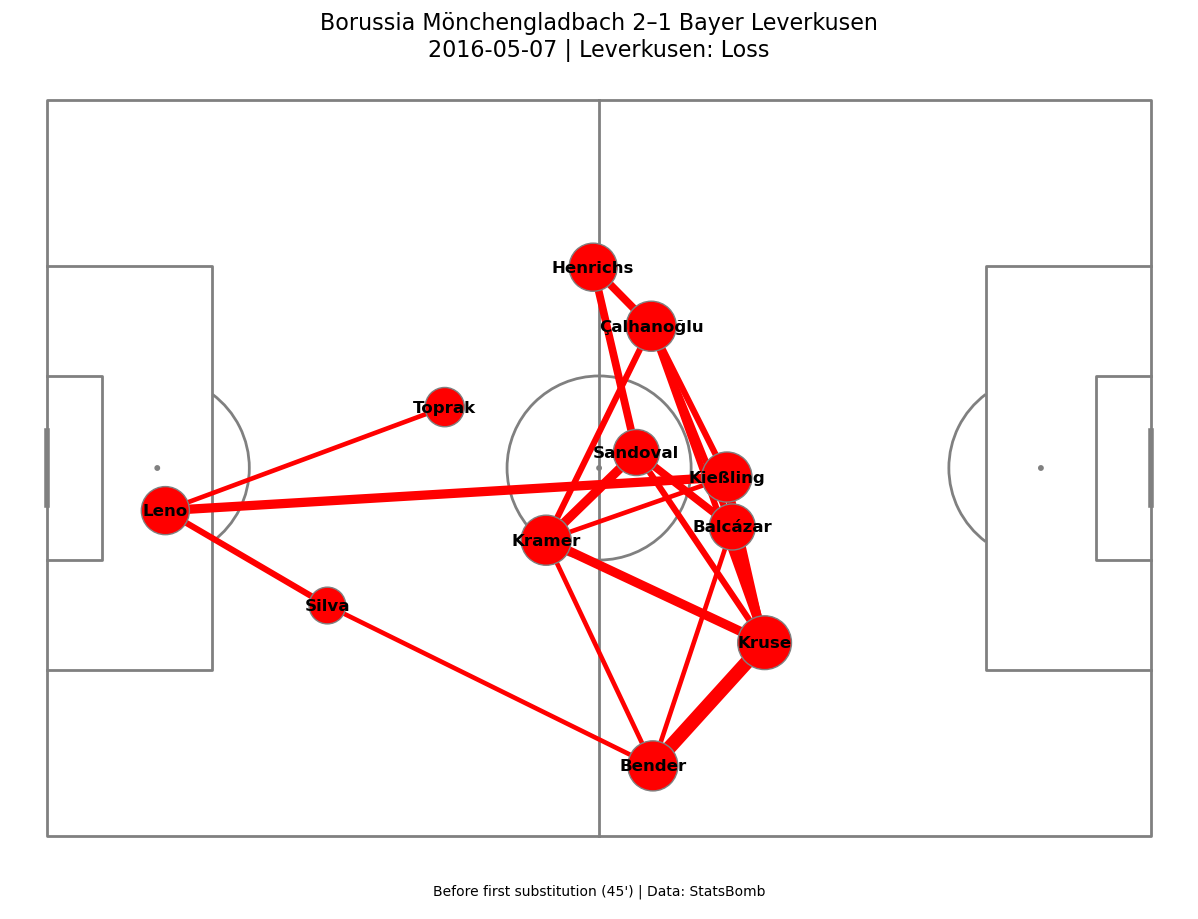

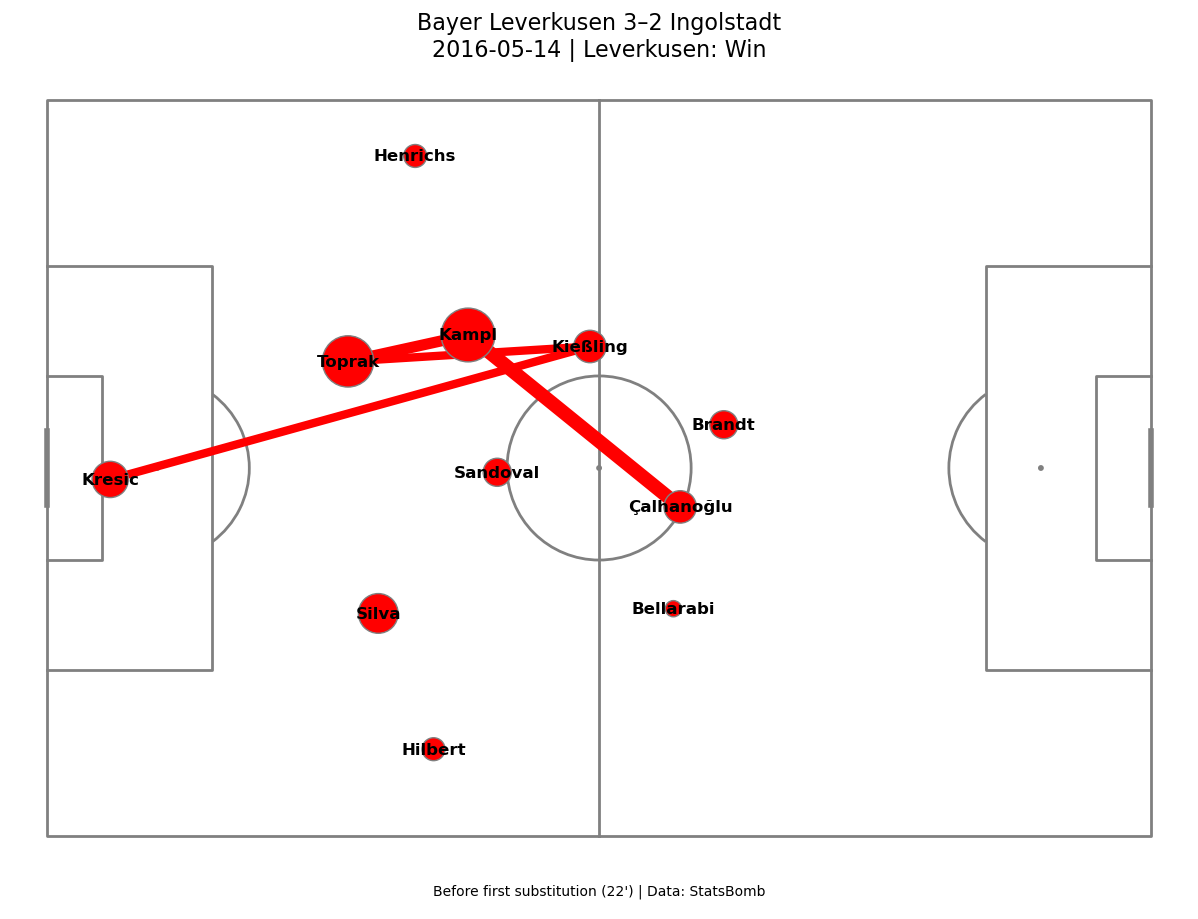

,match_id,date,opponent,venue,goals_for,goals_against,result
0,3890260,2015-08-15,Hoffenheim,Home,2,1,Win
1,3890273,2015-08-22,Hannover 96,Away,1,0,Win
2,3890278,2015-08-29,Bayern Munich,Away,0,3,Loss
3,3890288,2015-09-12,Darmstadt 98,Home,0,1,Loss
4,3890301,2015-09-20,Borussia Dortmund,Away,0,3,Loss
5,3890312,2015-09-23,FSV Mainz 05,Home,1,0,Win
6,3890315,2015-09-26,Werder Bremen,Away,3,0,Win
7,3890330,2015-10-04,Augsburg,Home,1,1,Draw
8,3890337,2015-10-17,Hamburger SV,Away,0,0,Draw
9,3890346,2015-10-24,VfB Stuttgart,Home,4,3,Win


In [20]:
# Store each match's data separately using its match ID
season_networks = {}
results = []

for _, match in season_matches.iterrows():

    match_id = int(match["match_id"])
    home_team = match["home_team_name"]
    away_team = match["away_team_name"]
    home_score = int(match["home_score"])
    away_score = int(match["away_score"])
    date = pd.to_datetime(match["match_date"]).strftime("%Y-%m-%d")

    # Determine the result from Leverkusen's perspective
    if home_team == team:
        goals_for = home_score
        goals_against = away_score
        opponent = away_team
        venue = "Home"
    else:
        goals_for = away_score
        goals_against = home_score
        opponent = home_team
        venue = "Away"

    if goals_for > goals_against:
        result = "Win"
    elif goals_for < goals_against:
        result = "Loss"
    else:
        result = "Draw"

    results.append({
        "match_id": match_id,
        "date": date,
        "opponent": opponent,
        "venue": venue,
        "goals_for": goals_for,
        "goals_against": goals_against,
        "result": result,
    })

    # Load this match's events
    events, related, freeze, tactics = parser.event(match_id)

    # Find the first Leverkusen substitution
    substitutions = events.loc[
        (events["type_name"] == "Substitution")
        & (events["team_name"] == team)
    ].sort_values("index")

    if substitutions.empty:
        sub = float("inf")
        period_label = "Full match — no substitutions"
    else:
        sub = substitutions.iloc[0]["index"]
        sub_minute = int(substitutions.iloc[0]["minute"])
        period_label = f"Before first substitution ({sub_minute}')"

    # Successful passes, excluding throw-ins
    mask = (
        (events["type_name"] == "Pass")
        & (events["team_name"] == team)
        & (events["index"] < sub)
        & (events["outcome_name"].isnull())
        & (events["sub_type_name"] != "Throw-in")
    )

    passes = events.loc[
        mask,
        ["x", "y", "end_x", "end_y",
         "player_name", "pass_recipient_name"]
    ].dropna().copy()

    if passes.empty:
        print(f"No qualifying passes for match {match_id}")
        continue

    # Keep full names for grouping; shorten names only on the plot
    players = pd.unique(pd.concat([
        passes["player_name"],
        passes["pass_recipient_name"]
    ], ignore_index=True))

    nodes = pd.DataFrame()

    for i, name in enumerate(players):
        passx = passes.loc[passes["player_name"] == name, "x"].to_numpy()
        recx = passes.loc[
            passes["pass_recipient_name"] == name, "end_x"
        ].to_numpy()

        passy = passes.loc[passes["player_name"] == name, "y"].to_numpy()
        recy = passes.loc[
            passes["pass_recipient_name"] == name, "end_y"
        ].to_numpy()

        nodes.at[i, "player_name"] = name
        nodes.at[i, "x"] = np.mean(np.concatenate([passx, recx]))
        nodes.at[i, "y"] = np.mean(np.concatenate([passy, recy]))
        nodes.at[i, "no"] = (passes["player_name"] == name).sum()

    nodes["marker_size"] = nodes["no"] / nodes["no"].max() * 1500

    # Count passes between each pair, combining both directions
    passes["pair_key"] = passes.apply(
        lambda row: tuple(sorted([
            row["player_name"], row["pass_recipient_name"]
        ])),
        axis=1
    )

    lines = (
        passes.groupby("pair_key")
        .size()
        .reset_index(name="pass_count")
    )
    lines = lines.loc[lines["pass_count"] > 2].copy()

    # Retain each match's data without overwriting earlier matches
    season_networks[match_id] = {
        "events": events,
        "passes": passes,
        "nodes": nodes,
        "lines": lines,
        "result": result,
    }

    # Draw the network
    pitch = Pitch(line_color="grey")
    fig, ax = pitch.grid(
        grid_height=0.9,
        title_height=0.06,
        axis=False,
        endnote_height=0.04,
        title_space=0,
        endnote_space=0
    )

    pitch.scatter(
        nodes.x, nodes.y,
        s=nodes.marker_size,
        color="red",
        edgecolors="grey",
        linewidth=1,
        alpha=1,
        ax=ax["pitch"],
        zorder=3
    )

    for _, row in nodes.iterrows():
        pitch.annotate(
            row.player_name.split()[-1],
            xy=(row.x, row.y),
            c="black",
            va="center",
            ha="center",
            weight="bold",
            size=12,
            ax=ax["pitch"],
            zorder=4
        )

    positions = nodes.set_index("player_name")

    for _, row in lines.iterrows():
        player1, player2 = row["pair_key"]

        line_width = row["pass_count"] / lines["pass_count"].max() * 10

        pitch.lines(
            positions.loc[player1, "x"],
            positions.loc[player1, "y"],
            positions.loc[player2, "x"],
            positions.loc[player2, "y"],
            alpha=1,
            lw=line_width,
            zorder=2,
            color="red",
            ax=ax["pitch"]
        )

    ax["title"].text(
        0.5, 0.5,
        f"{home_team} {home_score}–{away_score} {away_team}\n"
        f"{date} | Leverkusen: {result}",
        ha="center", va="center", fontsize=16
    )

    ax["endnote"].text(
        0.5, 0.5,
        f"{period_label} | Data: StatsBomb",
        ha="center", va="center", fontsize=10
    )

    plt.show()
    plt.close(fig)

# A separate dataframe containing all match results
results_df = pd.DataFrame(results)
display(results_df)

In [24]:
from matplotlib.backends.backend_pdf import PdfPages
from pathlib import Path

output_path = Path("Leverkusen_2015_16_Passing_Networks.pdf")

# Include matches with an available passing network
plot_matches = results_df[
    results_df["match_id"].isin(season_networks)
].reset_index(drop=True)

plots_per_page = 6

with PdfPages(output_path) as pdf:

    for start in range(0, len(plot_matches), plots_per_page):

        # A4 landscape: 2 columns × 3 rows
        fig, axes = plt.subplots(
            nrows=3,
            ncols=2,
            figsize=(11.69, 8.27)
        )

        fig.suptitle(
            "Bayer Leverkusen | Bundesliga 2015/16\nPassing Networks",
            fontsize=16,
            fontweight="bold"
        )

        page_matches = plot_matches.iloc[start:start + plots_per_page]

        for ax, (_, match) in zip(axes.flat, page_matches.iterrows()):

            match_id = int(match["match_id"])
            network = season_networks[match_id]

            nodes = network["nodes"]
            lines = network["lines"]

            pitch = Pitch(line_color="grey", linewidth=0.7)
            pitch.draw(ax=ax)

            # Draw connections
            positions = nodes.set_index("player_name")

            for _, row in lines.iterrows():
                player1, player2 = row["pair_key"]

                line_width = (
                    row["pass_count"] / lines["pass_count"].max() * 5
                )

                pitch.lines(
                    positions.loc[player1, "x"],
                    positions.loc[player1, "y"],
                    positions.loc[player2, "x"],
                    positions.loc[player2, "y"],
                    lw=line_width,
                    color="red",
                    alpha=0.7,
                    zorder=2,
                    ax=ax
                )

            # Draw players
            pitch.scatter(
                nodes["x"],
                nodes["y"],
                s=nodes["marker_size"] * 0.18,
                color="red",
                edgecolors="grey",
                linewidth=0.5,
                zorder=3,
                ax=ax
            )
            
            nodes = network["nodes"]
            lines = network["lines"]
            pass_counts = nodes["no"]
            max_no = pass_counts.max()
            denominator = 10 * pass_counts.sum()
            nominator = (max_no - pass_counts).sum()

            centralisation_score = (nominator / denominator if denominator > 0 else float("nan"))

            # Store the score with the match's network
            network["centralisation"] = centralisation_score

            for _, row in nodes.iterrows():
                pitch.annotate(
                    row["player_name"].split()[-1],
                    xy=(row["x"], row["y"]),
                    ha="center",
                    va="center",
                    fontsize=6,
                    fontweight="bold",
                    zorder=4,
                    ax=ax
                )

            result_color = {
                "Win": "darkgreen",
                "Loss": "firebrick",
                "Draw": "darkorange"
            }[match["result"]]

            ax.set_title(
                f"{match['date']} | vs {match['opponent']} "
                f"({match['venue']})\n"
                f"Leverkusen {int(match['goals_for'])}–"
                f"{int(match['goals_against'])} Opponent | "
                f"{match['result']}\n"
                f"Centralisation: {centralisation_score:.3f}",
                fontsize=8,
                color=result_color,
                pad=5
            )

        # Hide unused panels on the final page
        for ax in list(axes.flat)[len(page_matches):]:
            ax.axis("off")

        page_number = start // plots_per_page + 1

        fig.text(
            0.5, 0.02,
            "Successful passes before first substitution; throw-ins excluded.\n"
            "Sizes scaled within each match | Full-match results | "
            f"Data: StatsBomb | Page {page_number}",
            ha="center",
            fontsize=7
        )

        fig.tight_layout(rect=[0, 0.06, 1, 0.91])
        pdf.savefig(fig)
        plt.close(fig)

print(f"PDF saved to: {output_path.resolve()}")

PDF saved to: /home/jovyan/Leverkusen_2015_16_Passing_Networks.pdf
